# Obligatorio final — Deep Learning
## ¿Es un recibo de sueldo? Clasificador de documentos con transfer learning

**Integrantes:**
- Eugenia Birriel
- Federico Vecchio

**Curso:** Deep Learning — Especialización en Economía, perfil Ciencia de Datos
**Fecha:** 11/12/2026

---

### El problema

Al intentar abrir una Cuenta Sueldo a través de eBROU se le pide a la persona que suba su **recibo de sueldo**. Hoy alguien revisa a mano que lo que se subió sea efectivamente un recibo. La idea es entrenar un modelo que, dada una imagen, diga si es un recibo de sueldo o no --> los casos claros se resuelven solos y a revisión manual van solo los dudosos.

### El enfoque, en una tabla

| | |
|---|---|
| **Datos de entrenamiento y validación** | 360 documentos **sintéticos** (180 recibos, 180 no recibos) generados por nosotros. No existe un dataset público de recibos uruguayos, y no usamos documentación real de clientes. |
| **Datos de test** | 22 documentos **reales** (15 recibos, 7 no recibos), que se miran **una sola vez**, al final (sección 12). |
| **Partición train/val** | **Agrupada por familia de documento**: plantillas enteras quedan afuera del entrenamiento (sección 4). |
| **Modelos** | Transfer learning con dos backbones: **ResNet-18** (ImageNet, como en la clase 10) y **DiT** (un transformer pre-entrenado en 42 millones de imágenes de documentos). Cada uno en dos versiones: backbone congelado y fine-tuning. |
| **Evaluación** | Piso con un "modelo tonto", curvas de train/val, matriz de confusión, umbral elegido según el costo de cada error, test real separado en diseños conocidos y no vistos, y mapas de oclusión para ver dónde mira el modelo. |

### Cómo correrlo

1. En Colab: *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)*. En CPU también corre, pero el fine-tuning de DiT tarda bastante más.
2. Correr las celdas en orden. La primera monta Google Drive y busca los datos en la carpeta del obligatorio (sección 1).
3. Tiempo total aproximado en GPU T4: 10-15 minutos.

> **Uso de IA.** El código fue generado con asistencia de IA (Claude) y revisado celda por celda por el equipo. Las decisiones de diseño (problema, datos, partición, criterio de evaluación) son nuestras y están justificadas en cada sección.

- Agregar fotos cualquiera (perro, selfie, etc)

### Índice

0. Portada
1. Entorno, datos y semilla
2. Los datos
3. El piso: ¿se puede acertar sin mirar el documento?
4. La partición: por qué agrupada por familia
5. Preprocesamiento y `Dataset`
6. El loop de entrenamiento
7. Modelo A: ResNet-18 (ImageNet)
8. Modelo B: DiT (documentos)
9. Comparación en validación y elección del modelo
10. ¿Cuánto nos hubiera mentido la partición estratificada?
11. El umbral: qué error preferimos
12. El sobre cerrado: test con documentos reales
13. ¿Dónde miró el modelo? (oclusión)
14. Reproducibilidad y ficha del modelo
15. Conclusiones y caminos para seguir

---
## 1. Entorno, datos y semilla

### 1.1 Montar Drive y ubicar los datos

Los datos viven en la carpeta del obligatorio en Google Drive:

- `Generador/datos_sinteticos.zip` → los 360 documentos sintéticos + `metadata.csv`.
- `Recibos/Reales`, `Recibos/Plantillas` y `Doc_varios_no_recibos` → los documentos reales para el test.

Fuera de Colab la celda no monta nada: toma la ruta de la variable de entorno `CARPETA_OBLIGATORIO`.

Instalamos dos bibliotecas si faltan:
- `transformers` (Hugging Face), para bajar DiT. Ya la usamos en las clases 9 y 10.
- `pymupdf`. ⚠️ **No visto en clase.** La necesitamos porque 6 de los recibos reales (BROU y Accesa) vienen en PDF y hay que convertirlos a imagen para dárselos al modelo.

*TODO (entrega): cuando armemos la carpeta exclusiva para el docente, cambiar `CARPETA_OBLIGATORIO` por la ruta de esa carpeta.*

In [ ]:
import os
import pathlib
import subprocess
import sys


def en_colab() -> bool:
    """¿Estamos en Google Colab? (la misma función del bootstrap de los notebooks del curso)"""
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False


# Instalamos sólo lo que falte (en Colab, transformers ya viene; pymupdf no)
faltan = []
for modulo, paquete in [("transformers", "transformers"), ("pymupdf", "pymupdf")]:
    try:
        __import__(modulo)
    except ImportError:
        faltan.append(paquete)
if faltan:
    print("Instalando:", ", ".join(faltan))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltan], check=True)

if en_colab():
    from google.colab import drive
    drive.mount("/content/drive")
    # "Mi unidad" de Drive se ve en Colab como /content/drive/MyDrive
    CARPETA_OBLIGATORIO = pathlib.Path(
        "/content/drive/MyDrive/Estudios/Posgrado CD/Deep Learning/Obligatorio final")
    CARPETA_TRABAJO = pathlib.Path("/content/trabajo")      # disco local de Colab: más rápido que leer de Drive
else:
    CARPETA_OBLIGATORIO = pathlib.Path(os.environ.get("CARPETA_OBLIGATORIO", "Obligatorio final"))
    CARPETA_TRABAJO = pathlib.Path(os.environ.get("CARPETA_TRABAJO", "trabajo"))

ZIP_SINTETICOS = CARPETA_OBLIGATORIO / "Generador" / "datos_sinteticos.zip"

# Chequeo: ¿está todo donde lo esperamos?
for ruta in [ZIP_SINTETICOS,
             CARPETA_OBLIGATORIO / "Recibos" / "Reales",
             CARPETA_OBLIGATORIO / "Recibos" / "Plantillas",
             CARPETA_OBLIGATORIO / "Doc_varios_no_recibos"]:
    print(("OK     " if ruta.exists() else "FALTA  ") + str(ruta))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OK     /content/drive/MyDrive/Estudios/Posgrado CD/Deep Learning/Obligatorio final/Generador/datos_sinteticos.zip
OK     /content/drive/MyDrive/Estudios/Posgrado CD/Deep Learning/Obligatorio final/Recibos/Reales
OK     /content/drive/MyDrive/Estudios/Posgrado CD/Deep Learning/Obligatorio final/Recibos/Plantillas
OK     /content/drive/MyDrive/Estudios/Posgrado CD/Deep Learning/Obligatorio final/Doc_varios_no_recibos


### 1.2 Imports, semilla y parámetros generales

Semilla **1983**, la del curso: no mejora el modelo, hace que el resultado sea **reproducible** (clase 4). Los hiperparámetros que se tocan seguido quedan todos en esta celda.

- `TAM = 224`: el tamaño de entrada con el que se pre-entrenaron los dos backbones.
- `EPOCAS` y `PACIENCIA`: entrenamos hasta 15 épocas, pero con *early stopping* (clase 4) --> si la loss de validación no mejora en 4 épocas seguidas, paramos y nos quedamos con la mejor época.
- `MODELO_DIT`: el checkpoint de DiT en Hugging Face (sección 8).

In [ ]:
import copy
import hashlib
import platform
import random
import time
import zipfile
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf
import torch
import torch.nn as nn
import torchvision
import transformers
from PIL import Image, ImageOps
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import (GroupKFold, LeaveOneGroupOut, StratifiedKFold,
                                     cross_val_predict, cross_val_score, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from transformers import AutoImageProcessor, AutoModel, AutoModelForImageClassification

SEMILLA = 1983


def fijar_semilla(semilla: int = SEMILLA) -> None:
    """numpy + random + torch (CPU y GPU), todo de una."""
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.cuda.manual_seed_all(semilla)


fijar_semilla()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- Parámetros generales ----------------------------------------------------
TAM = 224            # alto y ancho de entrada de los dos backbones
BATCH = 16           # documentos por lote
EPOCAS = 15          # máximo de épocas por entrenamiento
PACIENCIA = 4        # early stopping: épocas sin mejorar la loss de validación antes de parar
MODELO_DIT = "microsoft/dit-base-finetuned-rvlcdip"
REVISION_DIT = None  # TODO (opcional): fijar el hash del commit, como piden las clases 9 y 10. La sección 14 imprime cuál se usó.

print(f"PyTorch {torch.__version__} | transformers {transformers.__version__} | device: {device}")
if device.type == "cpu":
    print("[!] Sin GPU: corre igual, pero el fine-tuning de DiT va a tardar bastante más.")

PyTorch 2.14.1+cu130 | transformers 5.22.1 | device: cuda


---
## 2. Los datos

### 2.1 De dónde salen

No se encontró un dataset público de recibos de sueldo uruguayos, y no corresponde usar documentación real de clientes del banco para un trabajo del curso. Por eso **generamos nuestros propios documentos** con un script en Python (`Generador/generador_recibos.py`, semilla 42). El generador reconstruye cada formato como una plantilla con parámetros que varían (fuentes, márgenes, bordes, cantidad de conceptos) y la llena con datos ficticios pero coherentes: C.I. con dígito verificador válido y liquidación que cierra (líquido = haberes − descuentos). Todas las empresas y marcas son inventadas.

| | cantidad | de qué |
|---|---|---|
| **Recibos** (etiqueta 1) | 180 = 9 familias × 20 | BROU web, BROU sistema viejo, genérico limpio, BPS por períodos, tabla densa (construcción), impresora de matriz, listado largo (Udelar), dos columnas lado a lado, formulario completado a mano |
| **No recibos** (etiqueta 0) | 180 = 11 categorías × 16-17 | factura, estado de cuenta, ticket, presupuesto, constancia laboral, factura de servicios, planilla de horas, recibo de pago, carta, tributo municipal, **recibo vacío** |

- **Recibo vacío = no recibo.** Un formulario de recibo sin completar no tiene validez como comprobante de ingresos. Es el negativo más difícil, a propósito.
- **Cada imagen sale en uno de tres modos** (`modo_aug`), igual para las dos clases: `foto` (perspectiva, fondo, sombras, arrugas, a veces girada 90°), `escaneo` y `digital` (limpio). Así el modelo no puede usar "foto vs. escaneo" para separar las clases.

**Se entrena y se valida sólo con sintéticos.** Los documentos reales quedan para el test (sección 12).

Descomprimimos el zip en el disco local de Colab y leemos `metadata.csv`, que trae una fila por imagen.

In [ ]:
CARPETA_SINTETICOS = CARPETA_TRABAJO / "datos_sinteticos"

if not (CARPETA_SINTETICOS / "metadata.csv").exists():          # se descomprime una sola vez por sesión
    CARPETA_SINTETICOS.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_SINTETICOS) as z:
        z.extractall(CARPETA_SINTETICOS)

meta = pd.read_csv(CARPETA_SINTETICOS / "metadata.csv")
meta["ruta"] = [str(CARPETA_SINTETICOS / a) for a in meta["archivo"]]
assert all(os.path.exists(r) for r in meta["ruta"]), "Hay archivos del metadata que no están en el zip"

# familia: la plantilla del recibo, o la categoría del no-recibo --> es la unidad de agrupación de la sección 4
print(f"{len(meta)} imágenes · {meta['familia'].nunique()} familias")
meta.head()

360 imágenes · 20 familias


,archivo,etiqueta,clase,familia,subtipo,modo_aug,semilla,ruta
0,positivos/bloques_000.jpg,1,recibo,bloques,bloques,foto,4200000,/content/trabajo/datos_sinteticos/positivos/bl...
1,positivos/bloques_001.jpg,1,recibo,bloques,bloques,escaneo,4200001,/content/trabajo/datos_sinteticos/positivos/bl...
2,positivos/bloques_002.jpg,1,recibo,bloques,bloques,digital,4200002,/content/trabajo/datos_sinteticos/positivos/bl...
3,positivos/bloques_003.jpg,1,recibo,bloques,bloques,foto,4200003,/content/trabajo/datos_sinteticos/positivos/bl...
4,positivos/bloques_004.jpg,1,recibo,bloques,bloques,foto,4200004,/content/trabajo/datos_sinteticos/positivos/bl...


### 2.2 Composición

Para confirmar el balance entre clases y que el modo de captura esté repartido igual en las dos.

In [ ]:
print(meta["clase"].value_counts().to_string(), "\n")

# Proporción de cada modo de captura dentro de cada clase: tiene que ser parecida en las dos
print(pd.crosstab(meta["clase"], meta["modo_aug"], normalize="index").round(2), "\n")

pd.crosstab([meta["clase"], meta["familia"]], meta["modo_aug"], margins=True)

clase
recibo       180
no_recibo    180 

modo_aug   digital  escaneo  foto
clase                            
no_recibo     0.31     0.19  0.49
recibo        0.29     0.21  0.50 



modo_aug                      digital  escaneo  foto  All
clase     familia                                        
no_recibo carta                     4        3     9   16
          constancia_laboral        3        3    10   16
          estado_cuenta             4        7     6   17
          factura                   3        2    12   17
          factura_servicios         7        1     8   16
          planilla_horas            4        2    10   16
          presupuesto               7        3     7   17
          recibo_pago               7        2     7   16
          recibo_vacio              8        2     6   16
          ticket                    3        6     8   17
          tributo_municipal         6        4     6   16
recibo    bloques                   6        7     7   20
          formulario                3        4    13   20
          generico_limpio           4        5    11   20
          lado_a_lado               8        2    10   20
          listado_largo             7        4     9   20
          matriz                    5        2    13   20
          periodos                  5        6     9   20
          sistema_viejo             9        2     9   20
          tabla_densa               5        6     9   20
All                               108       73   179  360

### 2.3 Mirarlos

Antes de entrenar nada, conviene mirar los datos. Una fila de recibos y una de no recibos, al azar.

`cargar_imagen` es la **única** puerta de entrada de imágenes en todo el notebook: abre JPG, PNG, WEBP o la primera página de un PDF, y devuelve la imagen en escala de grises (la razón de los grises está en la sección 5). Dos detalles:
- `ImageOps.exif_transpose`: las fotos de celular guardan la rotación aparte, en el EXIF. Si no la aplicamos, una foto puede entrar acostada.
- Las imágenes con transparencia se pegan sobre fondo blanco. Si no, lo transparente se vuelve negro.

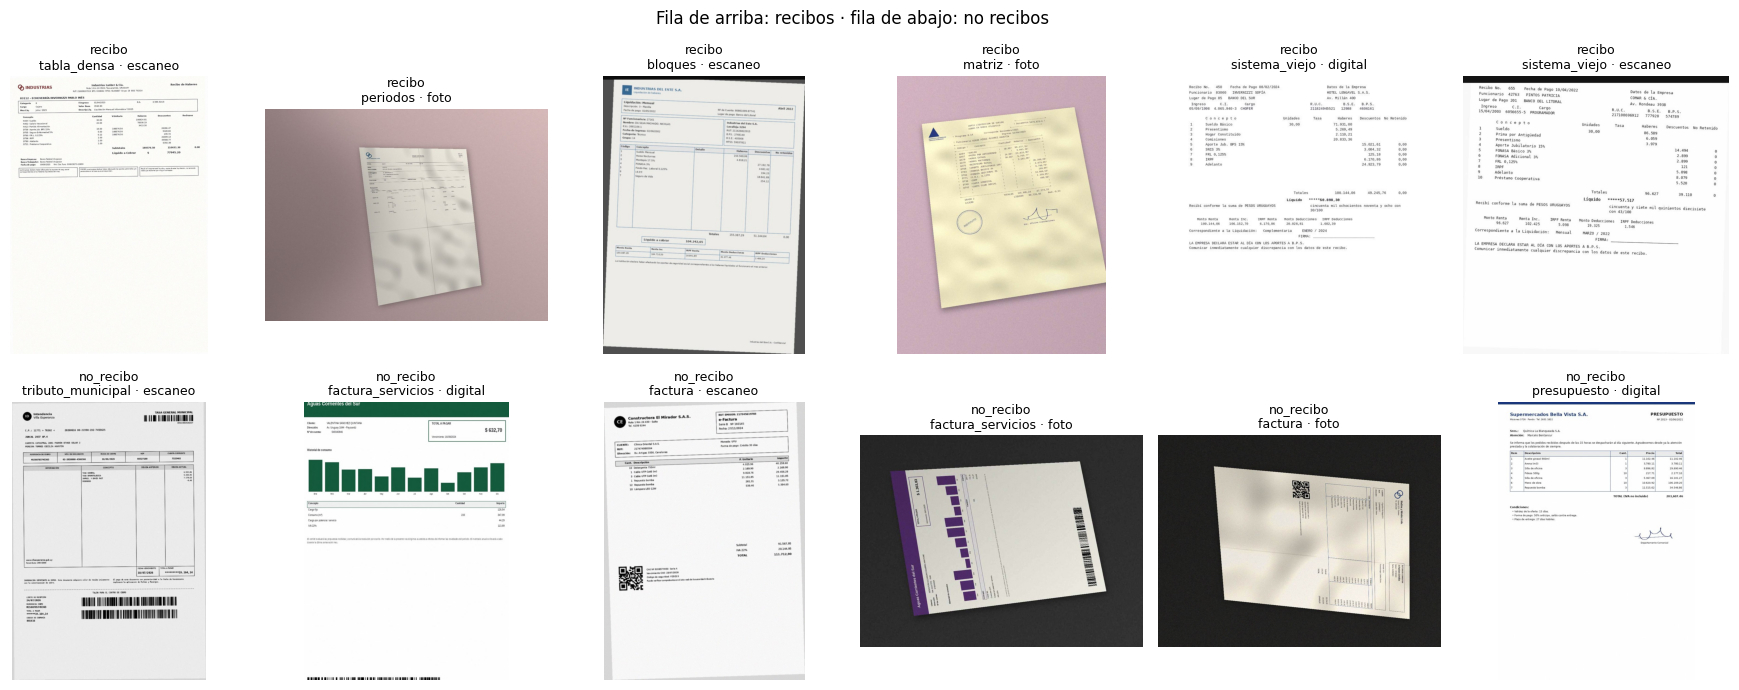

In [ ]:
DPI_PDF = 100   # resolución para pasar los PDF a imagen: deja una hoja A4 en ~830 x 1200 px, del orden de los sintéticos


def cargar_imagen(ruta: str) -> Image.Image:
    """Abre una imagen (o la 1.a página de un PDF) y la devuelve en escala de grises."""
    if str(ruta).lower().endswith(".pdf"):
        with pymupdf.open(ruta) as doc:
            pix = doc[0].get_pixmap(dpi=DPI_PDF)                      # renderiza la página como imagen
        img = Image.frombytes("RGB", (pix.width, pix.height), pix.samples)
    else:
        img = ImageOps.exif_transpose(Image.open(ruta))               # respeta la rotación de las fotos de celular
        if img.mode in ("RGBA", "LA", "P"):                           # transparencia --> fondo blanco
            img = img.convert("RGBA")
            img = Image.alpha_composite(Image.new("RGBA", img.size, "white"), img)
    return img.convert("L")


rng = np.random.default_rng(SEMILLA)
fig, ejes = plt.subplots(2, 6, figsize=(18, 7))
for fila, etiqueta in enumerate([1, 0]):
    muestra = rng.choice(meta.index[meta["etiqueta"] == etiqueta], 6, replace=False)
    for ax, i in zip(ejes[fila], muestra):
        ax.imshow(Image.open(meta.at[i, "ruta"]).convert("RGB"))     # a color, como salió del generador
        ax.set_title(f"{meta.at[i, 'clase']}\n{meta.at[i, 'familia']} · {meta.at[i, 'modo_aug']}", fontsize=9)
        ax.axis("off")
plt.suptitle("Fila de arriba: recibos · fila de abajo: no recibos", fontsize=12)
plt.tight_layout()
plt.show()

### 2.4 El test real (todavía en sobre cerrado)

22 documentos reales que **no se usan para nada** hasta la sección 12. Acá sólo armamos la tabla con su etiqueta y los separamos en dos grupos, porque no son todos igual de difíciles:

- **Con pariente sintético:** documentos reales que usamos como modelo para diseñar alguna familia del generador (BROU, BPS, construcción, Intendencia de Artigas, Udelar, genéricos), y los negativos cuya categoría existe en el generador (estados de cuenta, contribución, facturas de OSE, recibos vacíos). Acá esperamos que el modelo ande bien, y ese número es **optimista**.
- **Diseño no visto:** recibos de empresas que dejamos afuera del generador **a propósito** (Accesa, Anglo, Monfilco). Es la prueba más parecida al uso real: un recibo con un formato que el modelo nunca vio.

Notas sobre algunos archivos:
- `afap.png` es un recibo **argentino**. Lo dejamos como positivo porque suma variedad de formato.
- `udelar_sin_nombre.jpg` es un recibo completo al que le borraron el nombre --> sigue siendo recibo.
- Los dos `recibo_generico_sin_datos` son formularios **vacíos** --> no recibo, por la regla de la sección 2.1.

In [ ]:
CON_PARIENTE, NO_VISTO = "con pariente sintético", "diseño no visto"

filas_test = [
    # (carpeta, archivo, etiqueta, grupo, nota)
    ("Recibos/Reales", "recibo_mensual_brou1.pdf",        1, CON_PARIENTE, "BROU web"),
    ("Recibos/Reales", "recibo_complementario_brou.pdf",  1, CON_PARIENTE, "BROU web, complementario"),
    ("Recibos/Reales", "recibo_mensual_brou12.pdf",       1, CON_PARIENTE, "BROU sistema viejo"),
    ("Recibos/Reales", "bps.webp",                        1, CON_PARIENTE, "BPS por períodos"),
    ("Recibos/Reales", "construccion.webp",               1, CON_PARIENTE, "tabla densa"),
    ("Recibos/Reales", "intendencia_artigas.jpeg",        1, CON_PARIENTE, "impresora de matriz, foto"),
    ("Recibos/Plantillas", "udelar_sin_nombre.jpg",       1, CON_PARIENTE, "listado largo, sin nombre"),
    ("Recibos/Plantillas", "generico_con_datos.webp",     1, CON_PARIENTE, "genérico"),
    ("Recibos/Plantillas", "generico_con_datos2.webp",    1, CON_PARIENTE, "genérico"),
    ("Recibos/Plantillas", "afap.png",                    1, CON_PARIENTE, "recibo argentino"),
    ("Recibos/Reales", "accesa_1.pdf",                    1, NO_VISTO, "Accesa"),
    ("Recibos/Reales", "accesa_2.pdf",                    1, NO_VISTO, "Accesa"),
    ("Recibos/Reales", "accesa_3.pdf",                    1, NO_VISTO, "Accesa, dos recibos en una hoja"),
    ("Recibos/Reales", "anglo.jpeg",                      1, NO_VISTO, "Anglo"),
    ("Recibos/Reales", "monfilco.jpeg",                   1, NO_VISTO, "Monfilco, foto"),
    ("Doc_varios_no_recibos", "estado_cuenta_santander.jpeg", 0, CON_PARIENTE, "estado de cuenta tarjeta"),
    ("Doc_varios_no_recibos", "estado_cuenta_scotia.jpeg",    0, CON_PARIENTE, "estado de cuenta tarjeta, girado"),
    ("Doc_varios_no_recibos", "im_contribucion.jpeg",         0, CON_PARIENTE, "tributo municipal"),
    ("Doc_varios_no_recibos", "ose.jpeg",                     0, CON_PARIENTE, "factura de servicio"),
    ("Doc_varios_no_recibos", "ose2.jpeg",                    0, CON_PARIENTE, "factura de servicio"),
    ("Doc_varios_no_recibos", "recibo_generico_sin_datos.webp",  0, CON_PARIENTE, "recibo VACÍO"),
    ("Doc_varios_no_recibos", "recibo_generico_sin_datos2.webp", 0, CON_PARIENTE, "recibo VACÍO"),
]
df_test = pd.DataFrame(filas_test, columns=["carpeta", "archivo", "etiqueta", "grupo", "nota"])
df_test["ruta"] = [str(CARPETA_OBLIGATORIO / c / a) for c, a in zip(df_test["carpeta"], df_test["archivo"])]
assert all(os.path.exists(r) for r in df_test["ruta"]), "Falta algún documento de test"

pd.crosstab(df_test["grupo"], df_test["etiqueta"].map({1: "recibo", 0: "no recibo"}), margins=True)

etiqueta,no recibo,recibo,All
grupo,,,
con pariente sintético,7,10,17
diseño no visto,0,5,5
All,7,15,22


---
## 3. El piso: ¿se puede acertar sin mirar el documento?

Clase 4: **si no le ganás al modelo tonto, tu modelo no sirve**. Acá tenemos dos pisos:

1. **Adivinar la clase mayoritaria:** las clases están balanceadas --> 50 %.
2. **Un modelo tonto con rasgos superficiales:** una regresión logística que **no ve el contenido** del documento, sólo cinco números: proporción ancho/alto, tamaño en megapíxeles, brillo medio, contraste y saturación de color.

El segundo piso es, además, un **detector de atajos**. Si con esos cinco números se acierta mucho más del 50 %, el generador está dejando una pista que no tiene nada que ver con "ser un recibo", y la red la va a encontrar antes que nosotros. Es el problema que la pauta pide mirar: un modelo que aprende un atajo en lugar de lo que queremos medir.

Lo medimos con validación cruzada **agrupada por familia** (la misma lógica de la sección 4), y también estratificada, para comparar.

In [ ]:
def rasgos_superficiales(ruta: str) -> dict:
    """Cinco números que NO dicen nada sobre si el documento es un recibo."""
    img = ImageOps.exif_transpose(Image.open(ruta)).convert("RGB")
    gris = np.asarray(img.convert("L"), dtype=float) / 255
    saturacion = np.asarray(img.convert("HSV"), dtype=float)[..., 1] / 255
    ancho, alto = img.size
    return {"proporcion": ancho / alto,           # apaisado (>1) o vertical (<1)
            "megapixeles": ancho * alto / 1e6,
            "brillo": gris.mean(),
            "contraste": gris.std(),
            "saturacion": saturacion.mean()}       # cuánto color hay (papel amarillento, logos, etc.)


rasgos = pd.DataFrame([rasgos_superficiales(r) for r in meta["ruta"]])
y_sint = meta["etiqueta"].values
familias = meta["familia"].values

print("Promedio de cada rasgo por clase:")
print(rasgos.groupby(meta["clase"]).mean().round(3), "\n")

modelo_tonto = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
cv_agrupada = GroupKFold(n_splits=5)                                       # familias enteras de un lado
cv_estratificada = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

for nombre, columnas in [("los 5 rasgos", list(rasgos.columns)),
                         ("sin saturación (sin color)", [c for c in rasgos.columns if c != "saturacion"])]:
    acc_g = cross_val_score(modelo_tonto, rasgos[columnas], y_sint, cv=cv_agrupada, groups=familias)
    acc_e = cross_val_score(modelo_tonto, rasgos[columnas], y_sint, cv=cv_estratificada)
    print(f"Modelo tonto con {nombre:28s} agrupada: {acc_g.mean():.1%} ± {acc_g.std():.1%}   "
          f"estratificada: {acc_e.mean():.1%} ± {acc_e.std():.1%}")

print("\nPiso de referencia: 50 % (clases balanceadas).")

Promedio de cada rasgo por clase:
           proporcion  megapixeles  brillo  contraste  saturacion
clase                                                            
no_recibo       0.854        0.718   0.782      0.156       0.087
recibo          0.892        0.729   0.789      0.148       0.081 

Modelo tonto con los 5 rasgos                 agrupada: 43.3% ± 6.0%   estratificada: 49.2% ± 4.7%
Modelo tonto con sin saturación (sin color)   agrupada: 42.5% ± 5.7%   estratificada: 50.8% ± 4.0%

Piso de referencia: 50 % (clases balanceadas).


**Cómo leerlo.** Si el modelo tonto queda cerca del 50 %, el tamaño, la orientación, el brillo y el color no delatan la clase. Ese fue el objetivo de las correcciones que le hicimos al generador: en una versión anterior el 28 % de los recibos eran apaisados contra el 4 % de los negativos, y el modelo tonto acertaba el 58,6 %.

Un riesgo que sigue abierto es el **color**: la familia `matriz` (impresora de matriz) tiene papel amarillento y es positiva. La tabla de abajo muestra la saturación por familia. Por eso, en la sección 5, pasamos todas las imágenes a **escala de grises** antes de dárselas a la red --> esa pista desaparece por construcción.

In [ ]:
(rasgos.assign(familia=meta["familia"], clase=meta["clase"])
       .groupby(["clase", "familia"])[["saturacion", "proporcion", "brillo"]].mean()
       .round(3).sort_values("saturacion", ascending=False))

saturacion  proporcion  brillo
clase     familia                                           
recibo    matriz                   0.137       0.856   0.752
no_recibo carta                    0.133       0.965   0.759
          recibo_pago              0.121       0.920   0.807
          factura_servicios        0.112       0.932   0.714
          factura                  0.110       0.872   0.702
recibo    formulario               0.108       0.884   0.746
          tabla_densa              0.097       0.989   0.762
no_recibo ticket                   0.089       0.613   0.758
          planilla_horas           0.085       0.812   0.767
          constancia_laboral       0.075       0.775   0.795
recibo    sistema_viejo            0.075       0.914   0.813
          generico_limpio          0.074       1.007   0.774
no_recibo tributo_municipal        0.070       0.832   0.792
recibo    bloques                  0.070       0.798   0.804
          periodos                 0.068       0.825   0.846
no_recibo recibo_vacio             0.065       0.847   0.866
recibo    listado_largo            0.059       0.797   0.839
no_recibo estado_cuenta            0.058       0.924   0.872
          presupuesto              0.046       0.905   0.773
recibo    lado_a_lado              0.046       0.960   0.769

---
## 4. La partición: por qué agrupada por familia

### 4.1 La decisión

Cada familia tiene 16-20 documentos que salen **de la misma plantilla**: cambian los datos (nombres, montos, conceptos) y la captura (foto, escaneo, digital), pero el diseño es el mismo. Los documentos de una misma familia **no son independientes**. Es el mismo problema visto en la clase 4: los 36 discursos no eran 36 casos independientes porque eran siete presidentes. Acá la familia cumple el papel del presidente.

Hay dos formas de partir en entrenamiento y validación:

| | **Estratificada por familia** | **Agrupada por familia** |
|---|---|---|
| Qué hace | Reparte cada familia entre train y val en la misma proporción (ej.: 16 en train, 4 en val) | Familias **enteras** quedan de un solo lado: las de validación nunca se ven al entrenar |
| Qué mide la validación | Si el modelo reconoce **plantillas que ya vio** con otros datos | Si el modelo reconoce **un recibo con un diseño que nunca vio** |
| Resultado esperado | Optimista: train y val comparten diseño --> fuga de información (*data leakage*, clase 4) | Más honesto: es la situación real del banco, donde cada empleador tiene su propio formato |
| Precio | — | La validación depende de **qué** familias quedaron afuera --> más variable |

**Elegimos la agrupada.** La pregunta del proyecto es "¿esto es un recibo?" y no "¿esto es uno de los 9 diseños de recibo que conozco?". En el onboarding van a llegar recibos de cientos de empleadores con formatos que no están en nuestro generador. Una validación estratificada nos diría que el modelo anda muy bien sin poder distinguir si aprendió el concepto o memorizó las plantillas.

El precio (validación más variable) lo medimos en la sección 10, donde repetimos la partición muchas veces y comparamos las dos formas de partir. Ahí se ve con números cuánto más optimista da la estratificada.

### 4.2 Cómo partimos

- **Validación:** 2 familias de recibo + 2 categorías de no recibo, sorteadas con la semilla del curso (20 % de los datos, como el 80/20 de la clase 5). La validación queda balanceada (40 recibos y ~33 no recibos).
- **Excepción a propósito: `recibo_vacio` siempre va a entrenamiento.** Que un recibo vacío no es un recibo es una **definición nuestra** (sección 2.1), no algo que se pueda deducir del resto de los negativos. Si esa categoría queda afuera, el modelo nunca vio un ejemplo de la regla y no tiene cómo aprenderla. En la sección 10 se ve qué pasa cuando sí queda afuera.
- **Test:** no sale de los sintéticos. Son los 22 documentos reales de la sección 2.4.

In [ ]:
def particion_por_familia(meta: pd.DataFrame, n_fam_pos: int = 2, n_fam_neg: int = 2,
                          semilla: int = SEMILLA,
                          siempre_en_train: tuple = ("recibo_vacio",)) -> tuple:
    """Sortea familias enteras para validación. Devuelve (idx_train, idx_val, familias_val)."""
    rng = np.random.default_rng(semilla)
    fam_pos = sorted(meta.loc[meta["etiqueta"] == 1, "familia"].unique())
    fam_neg = sorted(f for f in meta.loc[meta["etiqueta"] == 0, "familia"].unique()
                     if f not in siempre_en_train)                           # recibo_vacio no se sortea
    familias_val = [str(f) for f in rng.choice(fam_pos, n_fam_pos, replace=False)]
    familias_val += [str(f) for f in rng.choice(fam_neg, n_fam_neg, replace=False)]
    en_val = meta["familia"].isin(familias_val).values
    return np.where(~en_val)[0], np.where(en_val)[0], familias_val


idx_train, idx_val, familias_val = particion_por_familia(meta)

print("Familias en VALIDACIÓN (nunca se ven al entrenar):", familias_val)
print(f"entrenamiento: {len(idx_train)} imágenes · {y_sint[idx_train].mean():.0%} recibos")
print(f"validación:    {len(idx_val)} imágenes · {y_sint[idx_val].mean():.0%} recibos")

# El chequeo que importa: ninguna familia de los dos lados
compartidas = set(meta["familia"].iloc[idx_train]) & set(meta["familia"].iloc[idx_val])
assert not compartidas, f"Familias en train y val a la vez: {compartidas}"
print("OK: ninguna familia aparece en train y en validación a la vez.")

Familias en VALIDACIÓN (nunca se ven al entrenar): ['generico_limpio', 'formulario', 'factura_servicios', 'constancia_laboral']
entrenamiento: 288 imágenes · 49% recibos
validación:    72 imágenes · 56% recibos
OK: ninguna familia aparece en train y en validación a la vez.


### 4.3 La partición estratificada, sólo para comparar

La armamos del mismo tamaño para poder medir, en la sección 10, cuánto nos habría mentido. `stratify=familia` (clase 9) asegura que cada familia aparezca en las dos partes en la misma proporción --> todas las familias quedan compartidas.

In [ ]:
idx_train_estr, idx_val_estr = train_test_split(
    np.arange(len(meta)), test_size=len(idx_val), stratify=meta["familia"], random_state=SEMILLA)

compartidas_estr = set(meta["familia"].iloc[idx_train_estr]) & set(meta["familia"].iloc[idx_val_estr])
print(f"Estratificada: {len(idx_train_estr)} train / {len(idx_val_estr)} val")
print(f"Familias que aparecen en train Y en val: {len(compartidas_estr)} de {meta['familia'].nunique()} "
      "--> la validación mira plantillas que el modelo ya conoce.")

Estratificada: 288 train / 72 val
Familias que aparecen en train Y en val: 20 de 20 --> la validación mira plantillas que el modelo ya conoce.


---
## 5. Preprocesamiento y `Dataset`

### 5.1 Las decisiones

Clase 10: **el preprocesamiento tiene que coincidir con el que vio la red al pre-entrenarse**. Además, en documentos hay decisiones propias:

| decisión | por qué |
|---|---|
| **Escala de grises** (replicada en 3 canales) | DiT se pre-entrenó con escaneos en gris (sección 8). Además elimina el atajo del color: el papel amarillento sólo aparece en la familia `matriz` (sección 3). Los backbones esperan 3 canales, así que copiamos el gris tres veces. |
| **Resize directo a 224×224, sin recortar** | En la clase 10 se usaba `RandomResizedCrop`, que recorta un pedazo de la foto. En una hormiga no importa, pero en un recibo lo que lo define es el **layout completo** (encabezado, tabla de haberes y descuentos, líquido al pie). Recortar puede dejar afuera justo eso. Deformar la proporción, además, esconde si la hoja era apaisada o vertical, que era otro atajo posible. |
| **Augmentation en entrenamiento, suave:** rotación ±3° y brillo/contraste ±20 % | El generador ya trae perspectiva, sombras, arrugas y rotaciones. Esto agrega una variación distinta en cada época para que el modelo no memorice píxel por píxel. Validación y test van sin augmentation. |
| **Normalización** según cada modelo | ResNet: media y desvío de ImageNet (clase 10). DiT: lo que diga su `AutoImageProcessor`. |

Como hay sólo 360 imágenes, las cargamos **una sola vez** ya en gris y a 224×224, y las guardamos en memoria. Así cada época no vuelve a leer y achicar los archivos del disco.

In [ ]:
def preparar(ruta: str) -> Image.Image:
    """cargar_imagen + resize directo a TAM x TAM (sin recortar, deformando si hace falta)."""
    return cargar_imagen(ruta).resize((TAM, TAM), Image.Resampling.LANCZOS)


t0 = time.time()
imagenes_sinteticas = [preparar(r) for r in meta["ruta"]]
print(f"{len(imagenes_sinteticas)} imágenes cargadas en memoria en {time.time() - t0:.0f} s "
      f"· tamaño {imagenes_sinteticas[0].size} · modo {imagenes_sinteticas[0].mode}")


def armar_transforms(media: list, desvio: list) -> dict:
    """Las transformaciones de entrenamiento (con augmentation) y de evaluación (sin)."""
    return {
        "train": transforms.Compose([
            transforms.RandomRotation(3, fill=255),                     # ±3°, rellenando con blanco (papel)
            transforms.ColorJitter(brightness=0.2, contrast=0.2),       # ±20 % de brillo y contraste
            transforms.Grayscale(num_output_channels=3),                # gris copiado en 3 canales
            transforms.ToTensor(),
            transforms.Normalize(media, desvio),
        ]),
        "val": transforms.Compose([                                     # determinística: siempre igual
            transforms.Grayscale(num_output_channels=3),
            transforms.ToTensor(),
            transforms.Normalize(media, desvio),
        ]),
    }

360 imágenes cargadas en memoria en 3 s · tamaño (224, 224) · modo L


### 5.2 `Dataset` y `DataLoader`

Las dos piezas de la clase 5: el `Dataset` es la pila de fichas (`datos[i]` devuelve una imagen y su etiqueta) y el `DataLoader` las reparte de a lotes, barajando en entrenamiento. Usamos una clase propia en lugar de `ImageFolder` (clase 10) porque las imágenes ya están en memoria y la partición viene de nuestros índices, no de carpetas.

In [ ]:
class DocumentosDataset(Dataset):
    """Imágenes ya cargadas en memoria + sus etiquetas + la transformación a aplicar."""

    def __init__(self, imagenes: list, etiquetas, transform):
        self.imagenes = imagenes
        self.etiquetas = np.asarray(etiquetas)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.imagenes)

    def __getitem__(self, i: int):
        return self.transform(self.imagenes[i]), int(self.etiquetas[i])


def armar_cargadores(idx_tr, idx_va, tfs: dict) -> dict:
    """DataLoaders de train (barajado, con augmentation) y val (sin barajar, sin augmentation)."""
    ds_tr = DocumentosDataset([imagenes_sinteticas[i] for i in idx_tr], y_sint[idx_tr], tfs["train"])
    ds_va = DocumentosDataset([imagenes_sinteticas[i] for i in idx_va], y_sint[idx_va], tfs["val"])
    return {"train": DataLoader(ds_tr, batch_size=BATCH, shuffle=True,
                                generator=torch.Generator().manual_seed(SEMILLA)),
            "val": DataLoader(ds_va, batch_size=64)}


def mostrar_tensor(x: torch.Tensor, ax, media: list, desvio: list, titulo: str = "") -> None:
    """Deshace la normalización para poder mirar la imagen."""
    img = x.numpy().transpose(1, 2, 0) * np.array(desvio) + np.array(media)
    ax.imshow(np.clip(img, 0, 1))
    ax.set_title(titulo, fontsize=9)
    ax.axis("off")

---
## 6. El loop de entrenamiento

Una sola función para los cuatro modelos, como en la clase 10. Adentro están las **cinco líneas** de la clase 4 (predecir, comparar, borrar, anotar, mover) con dos agregados ya vistos:

- **Early stopping** (clase 4): en cada época medimos la loss de validación. Si no mejora en `PACIENCIA` épocas, paramos. Al final, el modelo vuelve a los pesos de su **mejor** época, no de la última. Esos pesos los guardamos con una copia (`copy.deepcopy` en la clase 10; acá copiamos el `state_dict` a la CPU).
- **`modelo.eval()` + `torch.no_grad()`** para medir (clase 5): en validación no se mueven perillas.

La loss es `CrossEntropyLoss` con dos salidas (no recibo / recibo), igual que en la clase 10. La probabilidad de "recibo" sale del `softmax` y es la que usamos para el umbral de la sección 11.

In [ ]:
criterio = nn.CrossEntropyLoss()


def entrenar_una_epoca(modelo: nn.Module, cargador: DataLoader, optimizador) -> float:
    modelo.train()
    suma = 0.0
    for x, y in cargador:
        x, y = x.to(device), y.to(device)
        prediccion = modelo(x)                 # 1. PREDECIR
        perdida = criterio(prediccion, y)      # 2. COMPARAR
        optimizador.zero_grad()                # 3. BORRAR
        perdida.backward()                     # 4. ANOTAR
        optimizador.step()                     # 5. MOVER
        suma += perdida.item() * len(y)
    return suma / len(cargador.dataset)


@torch.no_grad()
def evaluar(modelo: nn.Module, cargador: DataLoader) -> dict:
    """Loss, exactitud y la probabilidad de 'recibo' para cada documento del cargador."""
    modelo.eval()
    suma, probs, etiquetas = 0.0, [], []
    for x, y in cargador:
        x, y = x.to(device), y.to(device)
        salida = modelo(x)
        suma += criterio(salida, y).item() * len(y)
        probs.append(torch.softmax(salida, dim=1)[:, 1].cpu())   # P(recibo)
        etiquetas.append(y.cpu())
    probs, etiquetas = torch.cat(probs).numpy(), torch.cat(etiquetas).numpy()
    return {"loss": suma / len(etiquetas),
            "exactitud": float(((probs >= 0.5) == etiquetas).mean()),
            "probs": probs, "etiquetas": etiquetas}


def contar_entrenables(modelo: nn.Module) -> int:
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)


def entrenar_modelo(modelo: nn.Module, optimizador, cargadores: dict, nombre: str,
                    epocas: int = EPOCAS, paciencia: int = PACIENCIA) -> tuple:
    """Entrena con early stopping sobre la loss de validación y devuelve el modelo en su mejor época."""
    fijar_semilla()
    historial = {"train": [], "val": [], "exactitud": []}
    mejor = {"loss": float("inf"), "epoca": 0, "estado": None}
    sin_mejora = 0
    t0 = time.time()
    print(f"=== {nombre} · {contar_entrenables(modelo):,} parámetros entrenables ===")
    for epoca in range(1, epocas + 1):
        loss_train = entrenar_una_epoca(modelo, cargadores["train"], optimizador)
        ev = evaluar(modelo, cargadores["val"])
        historial["train"].append(loss_train)
        historial["val"].append(ev["loss"])
        historial["exactitud"].append(ev["exactitud"])
        marca = ""
        if ev["loss"] < mejor["loss"] - 1e-4:                                   # mejoró --> guardamos la foto
            mejor = {"loss": ev["loss"], "epoca": epoca,
                     "estado": {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}}
            sin_mejora, marca = 0, "  <- mejor hasta ahora"
        else:
            sin_mejora += 1
        print(f"época {epoca:2d} | loss train {loss_train:.3f} | loss val {ev['loss']:.3f} "
              f"| aciertos val {ev['exactitud']:.1%}{marca}")
        if sin_mejora >= paciencia:
            print(f"early stopping: {paciencia} épocas sin mejorar")
            break
    modelo.load_state_dict(mejor["estado"])                                     # volvemos a la mejor época
    historial["mejor_epoca"] = mejor["epoca"]
    print(f"Mejor época: {mejor['epoca']} (loss val {mejor['loss']:.3f}) · {time.time() - t0:.0f} s\n")
    return modelo, historial


resultados = {}   # acá guardamos cada modelo entrenado con su historial, sus transforms y sus cargadores

---
## 7. Modelo A: ResNet-18 pre-entrenada en ImageNet

### 7.1 Por qué

Es el modelo de la clase 10: una CNN pre-entrenada con 1,2 millones de fotos (ImageNet), a la que se le cambia la cabeza de 1000 clases por una de 2. Es nuestro **baseline de transfer learning**: aprendió bordes, texturas y formas, pero nunca vio un documento como tal. La pregunta es cuánto le alcanza eso para distinguir un recibo de una factura, que se parecen bastante.

Las dos estrategias de la clase 10:
- **Feature extraction:** se congela todo el backbone y se entrena sólo la capa nueva (`fc`, 512 → 2), unos 1.000 parámetros.
- **Fine-tuning:** se entrena todo, con learning rate chico, para que los filtros se ajusten un poco sin destruirse.

Optimizador y learning rate: los mismos de la clase 10 (`SGD`, `lr=0.001`, `momentum=0.9`).

*Detalle:* con el backbone congelado, las capas de `BatchNorm` igual actualizan sus promedios en modo `train()`. Lo dejamos como en la clase 10.

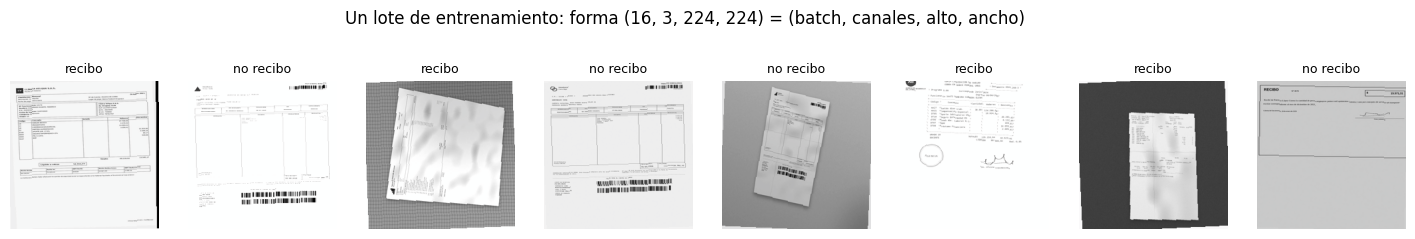

In [ ]:
IMAGENET_MEDIA = [0.485, 0.456, 0.406]
IMAGENET_DESVIO = [0.229, 0.224, 0.225]
tfs_resnet = armar_transforms(IMAGENET_MEDIA, IMAGENET_DESVIO)
cargadores_resnet = armar_cargadores(idx_train, idx_val, tfs_resnet)


def armar_resnet(congelar: bool) -> nn.Module:
    fijar_semilla()                                                   # misma cabeza inicial en cada corrida
    modelo = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    if congelar:
        for p in modelo.parameters():
            p.requires_grad = False                                   # el backbone no se mueve
    modelo.fc = nn.Linear(modelo.fc.in_features, 2)                   # cabeza nueva: 512 -> 2 (entrenable)
    return modelo.to(device)                                          # al device ANTES de crear el optimizador (clase 5)


# Así le llegan los documentos a la red: grises, 224x224, con la augmentation de entrenamiento
x_lote, y_lote = next(iter(cargadores_resnet["train"]))
fig, ejes = plt.subplots(1, 8, figsize=(18, 3))
for ax, x, y in zip(ejes, x_lote, y_lote):
    mostrar_tensor(x, ax, IMAGENET_MEDIA, IMAGENET_DESVIO, "recibo" if y == 1 else "no recibo")
plt.suptitle(f"Un lote de entrenamiento: forma {tuple(x_lote.shape)} = (batch, canales, alto, ancho)")
plt.show()

### 7.2 Feature extraction (backbone congelado)

In [ ]:
modelo = armar_resnet(congelar=True)
optimizador = torch.optim.SGD(modelo.fc.parameters(), lr=0.001, momentum=0.9)       # sólo la cabeza
modelo, historial = entrenar_modelo(modelo, optimizador, cargadores_resnet, "ResNet-18 congelada")
resultados["ResNet-18 congelada"] = {"modelo": modelo, "historial": historial, "tfs": tfs_resnet,
                                     "cargadores": cargadores_resnet}

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 199MB/s]


=== ResNet-18 congelada · 1,026 parámetros entrenables ===
época  1 | loss train 0.717 | loss val 0.860 | aciertos val 44.4%  <- mejor hasta ahora
época  2 | loss train 0.642 | loss val 0.738 | aciertos val 44.4%  <- mejor hasta ahora
época  3 | loss train 0.552 | loss val 0.965 | aciertos val 48.6%
época  4 | loss train 0.503 | loss val 1.005 | aciertos val 50.0%
época  5 | loss train 0.501 | loss val 0.791 | aciertos val 54.2%
época  6 | loss train 0.484 | loss val 0.821 | aciertos val 50.0%
early stopping: 4 épocas sin mejorar
Mejor época: 2 (loss val 0.738) · 8 s



### 7.3 Fine-tuning (todo entrenable)

In [ ]:
modelo = armar_resnet(congelar=False)
optimizador = torch.optim.SGD(modelo.parameters(), lr=0.001, momentum=0.9)          # todos los parámetros
modelo, historial = entrenar_modelo(modelo, optimizador, cargadores_resnet, "ResNet-18 fine-tuning")
resultados["ResNet-18 fine-tuning"] = {"modelo": modelo, "historial": historial, "tfs": tfs_resnet,
                                       "cargadores": cargadores_resnet}

=== ResNet-18 fine-tuning · 11,177,538 parámetros entrenables ===
época  1 | loss train 0.664 | loss val 0.699 | aciertos val 56.9%  <- mejor hasta ahora
época  2 | loss train 0.493 | loss val 1.114 | aciertos val 47.2%
época  3 | loss train 0.390 | loss val 1.352 | aciertos val 48.6%
época  4 | loss train 0.237 | loss val 1.222 | aciertos val 52.8%
época  5 | loss train 0.104 | loss val 1.397 | aciertos val 54.2%
early stopping: 4 épocas sin mejorar
Mejor época: 1 (loss val 0.699) · 7 s



---
## 8. Modelo B: DiT (Document Image Transformer)

### 8.1 Por qué

DiT (Microsoft, 2022) es un **transformer de imágenes**: parte la imagen en parches de 16×16 píxeles y trata cada parche como un token, con la misma atención de la clase 7. Lo que lo hace útil para nosotros es **con qué se pre-entrenó**:

1. Pre-entrenamiento **auto-supervisado** con **42 millones de imágenes de documentos** (IIT-CDIP): aprendió cómo son las tablas, los encabezados y los bloques de texto.
2. Ajuste supervisado con **RVL-CDIP**: 400.000 documentos en 16 clases (carta, formulario, factura, presupuesto, CV, etc.).

Usamos el checkpoint `microsoft/dit-base-finetuned-rvlcdip`, que ya pasó por los dos pasos. Con 288 imágenes de entrenamiento conviene partir del modelo que ya sabe clasificar documentos. Es la idea de "la forma de los datos manda": ResNet sabe de fotos, DiT sabe de documentos.

⚠️ **No visto en clase:** un modelo de **imágenes** de Hugging Face y su `AutoImageProcessor`. Es la misma mecánica que `AutoModel` + `AutoTokenizer` de la clase 10 (texto). El procesador cumple el papel del tokenizador: dice cómo hay que preparar la entrada (tamaño, media, desvío). Lo necesitamos porque `torchvision` no tiene modelos pre-entrenados en documentos.

### 8.2 ¿Qué sabe ya? (antes de tocar nada)

Como en la clase 10 con ResNet, primero usamos DiT **tal como viene**, con sus 16 clases de RVL-CDIP. No tiene una clase "recibo de sueldo", así que la pregunta es: ¿en qué clase de RVL-CDIP cae un recibo, y en cuál un no recibo? Si los recibos caen casi todos en una clase y los no recibos en otras, el modelo ya trae buena parte de la separación hecha. Lo miramos sólo sobre **entrenamiento**, para no espiar la validación.

In [ ]:
procesador_dit = AutoImageProcessor.from_pretrained(MODELO_DIT, revision=REVISION_DIT)
print(procesador_dit)                                               # tamaño, media y desvío que espera DiT

DIT_MEDIA = list(procesador_dit.image_mean)
DIT_DESVIO = list(procesador_dit.image_std)
tfs_dit = armar_transforms(DIT_MEDIA, DIT_DESVIO)
cargadores_dit = armar_cargadores(idx_train, idx_val, tfs_dit)

dit_original = AutoModelForImageClassification.from_pretrained(MODELO_DIT, revision=REVISION_DIT).to(device).eval()
clases_rvl = dit_original.config.id2label                           # las 16 clases de RVL-CDIP
print("Clases de RVL-CDIP:", list(clases_rvl.values()))

preprocessor_config.json:   0%|          | 0.00/302 [00:00<?, ?B/s]

BeitImageProcessor {
  "crop_size": {
    "height": 224,
    "width": 224
  },
  "do_center_crop": false,
  "do_normalize": true,
  "do_reduce_labels": false,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.5,
    0.5,
    0.5
  ],
  "image_processor_type": "BeitImageProcessor",
  "image_std": [
    0.5,
    0.5,
    0.5
  ],
  "reduce_labels": false,
  "resample": 2,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "height": 224,
    "width": 224
  }
}



config.json:   0%|          | 0.00/1.79k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  343MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

Clases de RVL-CDIP: ['letter', 'form', 'email', 'handwritten', 'advertisement', 'scientific report', 'scientific publication', 'specification', 'file folder', 'news article', 'budget', 'invoice', 'presentation', 'questionnaire', 'resume', 'memo']


model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

¿En qué clase de RVL-CDIP cae cada clase nuestra? (sólo entrenamiento)


clase,no_recibo,recibo
rvl_cdip,,
advertisement,36,16
budget,11,28
email,1,5
file folder,8,3
form,21,15
invoice,44,63
letter,9,3
presentation,2,1
questionnaire,0,2


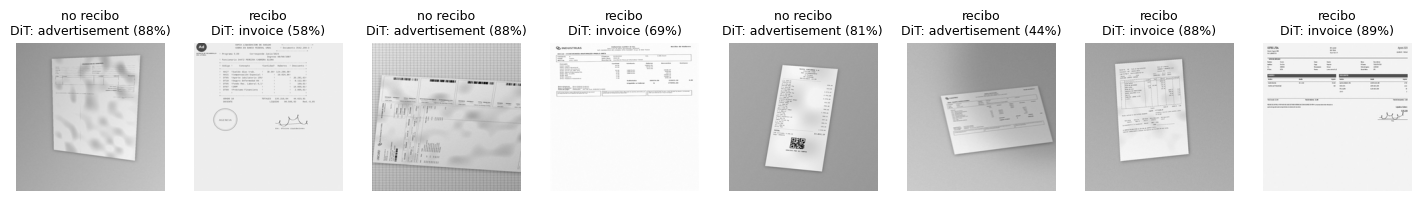

In [ ]:
ds_mirar = DocumentosDataset([imagenes_sinteticas[i] for i in idx_train], y_sint[idx_train], tfs_dit["val"])
clase_rvl, prob_rvl = [], []
with torch.no_grad():
    for x, _ in DataLoader(ds_mirar, batch_size=64):
        p = torch.softmax(dit_original(x.to(device)).logits, dim=1).cpu()
        prob_rvl += p.max(dim=1).values.tolist()
        clase_rvl += [clases_rvl[int(k)] for k in p.argmax(dim=1)]

dit_dice = meta.iloc[idx_train][["clase", "familia"]].assign(rvl_cdip=clase_rvl)
print("¿En qué clase de RVL-CDIP cae cada clase nuestra? (sólo entrenamiento)")
display(pd.crosstab(dit_dice["rvl_cdip"], dit_dice["clase"]))

# Unos ejemplos con lo que opina DiT sin ajustar
fig, ejes = plt.subplots(1, 8, figsize=(18, 3.6))
for ax, k in zip(ejes, np.random.default_rng(SEMILLA).choice(len(ds_mirar), 8, replace=False)):
    x, y = ds_mirar[k]
    mostrar_tensor(x, ax, DIT_MEDIA, DIT_DESVIO,
                   f"{'recibo' if y == 1 else 'no recibo'}\nDiT: {clase_rvl[k]} ({prob_rvl[k]:.0%})")
plt.show()

del dit_original                                                    # liberamos memoria: no lo usamos más

**Cómo leerlo.** Lo esperable es que muchos recibos caigan en *form* (formulario) o *invoice* (factura), y que los no recibos se repartan entre *invoice*, *letter*, *budget*, etc. La superposición en *invoice* y *form* es la parte que el fine-tuning tiene que resolver. Si un recibo y una factura caen en la misma clase, el modelo original no los distingue.

### 8.3 La cabeza nueva

Igual que en la clase 10 con DistilBERT: tomamos el **cuerpo** pre-entrenado con `AutoModel` (sin la cabeza de 16 clases) y le ponemos arriba una capa nueva `nn.Linear(768, 2)`. El vector que entra a la cabeza es el `pooler_output`, un resumen de 768 números de todo el documento.

Optimizador: `AdamW` (clase 9). Learning rate de `1e-3` cuando sólo se entrena la cabeza y de `5e-5` para el fine-tuning completo, el valor de la clase 9: con un transformer de 86 millones de parámetros, un paso grande destruye lo aprendido.

In [ ]:
class DiTClasificador(nn.Module):
    """Cuerpo de DiT pre-entrenado + cabeza nueva de 2 clases (mismo esquema que DistilBertClassifier, clase 10)."""

    def __init__(self, congelar_cuerpo: bool, n_clases: int = 2):
        super().__init__()
        self.cuerpo = AutoModel.from_pretrained(MODELO_DIT, revision=REVISION_DIT)   # sin la cabeza de RVL-CDIP
        self.dropout = nn.Dropout(0.1)
        self.cabeza = nn.Linear(self.cuerpo.config.hidden_size, n_clases)          # NUEVA: 768 -> 2
        if congelar_cuerpo:
            for p in self.cuerpo.parameters():
                p.requires_grad = False

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        vector = self.cuerpo(pixel_values=x).pooler_output                        # (batch, 768)
        return self.cabeza(self.dropout(vector))


def armar_dit(congelar: bool) -> nn.Module:
    fijar_semilla()
    return DiTClasificador(congelar_cuerpo=congelar).to(device)

### 8.4 Cuerpo congelado

In [ ]:
modelo = armar_dit(congelar=True)
optimizador = torch.optim.AdamW(modelo.cabeza.parameters(), lr=1e-3)               # sólo la cabeza
modelo, historial = entrenar_modelo(modelo, optimizador, cargadores_dit, "DiT congelado")
resultados["DiT congelado"] = {"modelo": modelo, "historial": historial, "tfs": tfs_dit,
                               "cargadores": cargadores_dit}

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

[transformers] BeitModel LOAD REPORT from: microsoft/dit-base-finetuned-rvlcdip
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


=== DiT congelado · 1,538 parámetros entrenables ===
época  1 | loss train 0.703 | loss val 0.628 | aciertos val 73.6%  <- mejor hasta ahora
época  2 | loss train 0.650 | loss val 0.609 | aciertos val 77.8%  <- mejor hasta ahora
época  3 | loss train 0.647 | loss val 0.606 | aciertos val 70.8%  <- mejor hasta ahora
época  4 | loss train 0.643 | loss val 0.592 | aciertos val 76.4%  <- mejor hasta ahora
época  5 | loss train 0.639 | loss val 0.598 | aciertos val 72.2%
época  6 | loss train 0.605 | loss val 0.549 | aciertos val 79.2%  <- mejor hasta ahora
época  7 | loss train 0.617 | loss val 0.555 | aciertos val 76.4%
época  8 | loss train 0.584 | loss val 0.549 | aciertos val 76.4%
época  9 | loss train 0.624 | loss val 0.577 | aciertos val 73.6%
época 10 | loss train 0.604 | loss val 0.555 | aciertos val 75.0%
early stopping: 4 épocas sin mejorar
Mejor época: 6 (loss val 0.549) · 42 s



### 8.5 Fine-tuning

In [ ]:
modelo = armar_dit(congelar=False)
optimizador = torch.optim.AdamW(modelo.parameters(), lr=5e-5, weight_decay=0.01)  # todo, con paso chico
modelo, historial = entrenar_modelo(modelo, optimizador, cargadores_dit, "DiT fine-tuning")
resultados["DiT fine-tuning"] = {"modelo": modelo, "historial": historial, "tfs": tfs_dit,
                                 "cargadores": cargadores_dit}

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

[transformers] BeitModel LOAD REPORT from: microsoft/dit-base-finetuned-rvlcdip
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


=== DiT fine-tuning · 85,809,410 parámetros entrenables ===
época  1 | loss train 0.669 | loss val 0.663 | aciertos val 51.4%  <- mejor hasta ahora
época  2 | loss train 0.508 | loss val 0.603 | aciertos val 68.1%  <- mejor hasta ahora
época  3 | loss train 0.332 | loss val 0.746 | aciertos val 63.9%
época  4 | loss train 0.183 | loss val 0.936 | aciertos val 59.7%
época  5 | loss train 0.126 | loss val 1.172 | aciertos val 56.9%
época  6 | loss train 0.101 | loss val 1.392 | aciertos val 58.3%
early stopping: 4 épocas sin mejorar
Mejor época: 2 (loss val 0.603) · 67 s



---
## 9. Comparación en validación y elección del modelo

### 9.1 Las curvas

Las curvas gemelas de la clase 4. La loss de validación es la que decide. Si la de train baja y la de val sube, hay sobreajuste ("la tijera").

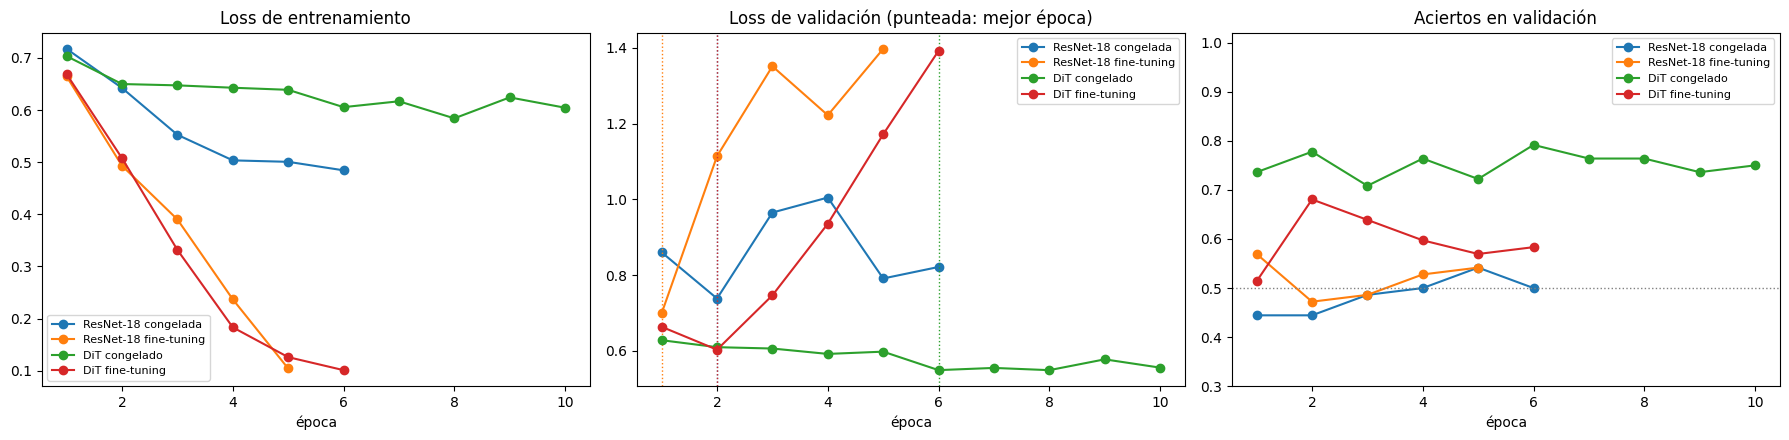

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(18, 4.5))
for nombre, r in resultados.items():
    h = r["historial"]
    epocas = range(1, len(h["train"]) + 1)
    linea, = ejes[0].plot(epocas, h["train"], marker="o", label=nombre)
    ejes[1].plot(epocas, h["val"], marker="o", color=linea.get_color(), label=nombre)
    ejes[1].axvline(h["mejor_epoca"], color=linea.get_color(), ls=":", lw=1)    # dónde frenó el early stopping
    ejes[2].plot(epocas, h["exactitud"], marker="o", color=linea.get_color(), label=nombre)
ejes[0].set(title="Loss de entrenamiento", xlabel="época")
ejes[1].set(title="Loss de validación (punteada: mejor época)", xlabel="época")
ejes[2].set(title="Aciertos en validación", xlabel="época", ylim=(0.3, 1.02))
ejes[2].axhline(0.5, color="gray", ls=":", lw=1)
for ax in ejes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 9.2 La tabla y la regla de elección

La regla, **antes** de ver los números: elegimos el modelo con mayor **F1 de la clase recibo** en validación, y si empatan, el de menor loss de validación. Usamos F1 y no exactitud porque nos importan los dos errores (dejar pasar un no recibo y rechazar un recibo). El umbral fino según el costo de cada error se decide después, en la sección 11.

In [ ]:
def metricas(etiquetas: np.ndarray, probs: np.ndarray, umbral: float = 0.5) -> dict:
    pred = (probs >= umbral).astype(int)
    return {"exactitud": accuracy_score(etiquetas, pred),
            "precision": precision_score(etiquetas, pred, zero_division=0),
            "recall": recall_score(etiquetas, pred, zero_division=0),
            "f1": f1_score(etiquetas, pred, zero_division=0)}


filas = []
for nombre, r in resultados.items():
    ev = evaluar(r["modelo"], r["cargadores"]["val"])
    r["eval_val"] = ev                                                   # lo guardamos para las secciones 11 y 13
    filas.append({"modelo": nombre, "entrenables": contar_entrenables(r["modelo"]),
                  "mejor_epoca": r["historial"]["mejor_epoca"], "loss_val": ev["loss"],
                  **metricas(ev["etiquetas"], ev["probs"])})
tabla_val = pd.DataFrame(filas).set_index("modelo")

MODELO_ELEGIDO = tabla_val.sort_values(["f1", "loss_val"], ascending=[False, True]).index[0]
elegido = resultados[MODELO_ELEGIDO]

print(f"Validación agrupada: {len(idx_val)} documentos de familias que ningún modelo vio ({familias_val})\n")
display(tabla_val.round(3))
print(f"\nModelo elegido: {MODELO_ELEGIDO}")

Validación agrupada: 72 documentos de familias que ningún modelo vio (['generico_limpio', 'formulario', 'factura_servicios', 'constancia_laboral'])



,entrenables,mejor_epoca,loss_val,exactitud,precision,recall,f1
modelo,,,,,,,
ResNet-18 congelada,1026,2,0.738,0.444,0.500,0.300,0.375
ResNet-18 fine-tuning,11177538,1,0.699,0.569,0.622,0.575,0.597
DiT congelado,1538,6,0.549,0.792,0.879,0.725,0.795
DiT fine-tuning,85809410,2,0.603,0.681,0.840,0.525,0.646



Modelo elegido: DiT congelado


### 9.3 El elegido, con su matriz de confusión y en castellano

La `reportar()` de la clase 9: **ninguna métrica sin su frase en castellano llano**.

DiT congelado · validación · umbral 0,5
· Precisión 0.88: de cada 100 documentos que el modelo llamó recibo, 88 lo eran.
· Recall 0.72: de cada 100 recibos verdaderos, el modelo reconoció 72.
· No recibos que dejó pasar como recibo (el error caro): 4 de 32.
· Recibos que rechazó (van a molestar al cliente o a revisión): 11 de 40.


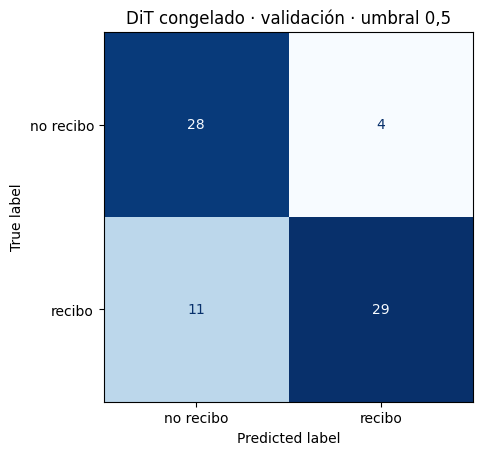

In [ ]:
def reportar(etiquetas: np.ndarray, pred: np.ndarray, titulo: str = "") -> None:
    """Matriz de confusión + las métricas dichas en castellano."""
    cm = confusion_matrix(etiquetas, pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    precision = tp / (tp + fp) if tp + fp else float("nan")
    recall = tp / (tp + fn) if tp + fn else float("nan")
    print(titulo)
    print(f"· Precisión {precision:.2f}: de cada 100 documentos que el modelo llamó recibo, {precision * 100:.0f} lo eran.")
    print(f"· Recall {recall:.2f}: de cada 100 recibos verdaderos, el modelo reconoció {recall * 100:.0f}.")
    print(f"· No recibos que dejó pasar como recibo (el error caro): {fp} de {tn + fp}.")
    print(f"· Recibos que rechazó (van a molestar al cliente o a revisión): {fn} de {tp + fn}.")
    ConfusionMatrixDisplay(cm, display_labels=["no recibo", "recibo"]).plot(cmap="Blues", colorbar=False)
    plt.title(titulo)
    plt.show()


ev = elegido["eval_val"]
reportar(ev["etiquetas"], (ev["probs"] >= 0.5).astype(int), f"{MODELO_ELEGIDO} · validación · umbral 0,5")

### 9.4 Los errores: mirarlos, no contarlos

Clase 5: los errores se miran. ¿De qué familia son? ¿Fotos, escaneos o digitales? ¿Hay un patrón?

Aciertos por familia y por modo de captura (validación):


mean  count
clase     familia                        
no_recibo constancia_laboral  0.75     16
          factura_servicios   1.00     16
recibo    formulario          0.65     20
          generico_limpio     0.80     20

,mean,count
modo_aug,,
digital,1.00,17
escaneo,1.00,13
foto,0.64,42



15 errores en 72 documentos de validación


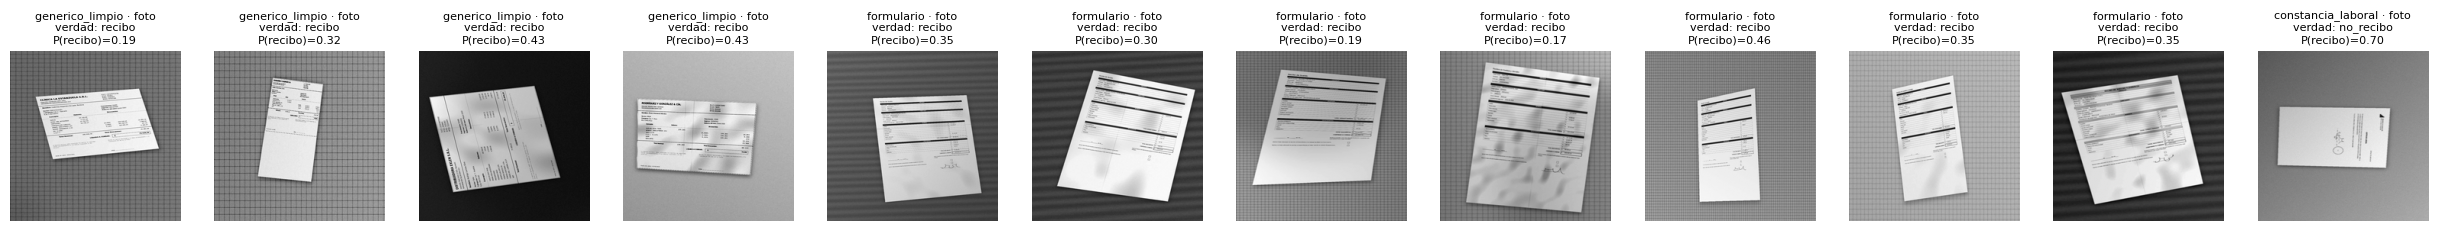

In [ ]:
val = meta.iloc[idx_val][["archivo", "clase", "familia", "subtipo", "modo_aug"]].copy()
val["p_recibo"] = ev["probs"]
val["acierto"] = (ev["probs"] >= 0.5).astype(int) == ev["etiquetas"]

print("Aciertos por familia y por modo de captura (validación):")
display(val.groupby(["clase", "familia"])["acierto"].agg(["mean", "count"]).round(2))
display(val.groupby("modo_aug")["acierto"].agg(["mean", "count"]).round(2))

errores = val[~val["acierto"]]
print(f"\n{len(errores)} errores en {len(val)} documentos de validación")
if len(errores):
    n = min(len(errores), 12)
    fig, ejes = plt.subplots(1, n, figsize=(2.6 * n, 3.8), squeeze=False)
    for ax, (i, fila) in zip(ejes[0], errores.head(n).iterrows()):
        ax.imshow(imagenes_sinteticas[i], cmap="gray")
        ax.set_title(f"{fila['familia']} · {fila['modo_aug']}\nverdad: {fila['clase']}\nP(recibo)={fila['p_recibo']:.2f}",
                     fontsize=8)
        ax.axis("off")
    plt.show()

---
## 10. ¿Cuánto nos hubiera mentido la partición estratificada? CANDIDATO A BORRAR

La sección 4 dice que la estratificada es optimista. Acá lo medimos.

**El experimento.** Entrenar cuatro redes con decenas de particiones distintas es caro. Pero con el backbone **congelado**, la red es "vector fijo + capa lineal": podemos calcular el vector de cada documento **una sola vez** y entrenar encima una regresión logística, que tarda milisegundos. Es la **estrategia A de la clase 9** (embeddings + regresión logística), con imágenes en vez de texto, y es equivalente a la feature extraction de las secciones 7.2 y 8.4.

Con eso hacemos tres cosas:
1. **20 particiones estratificadas vs. 20 agrupadas**, cambiando sólo la semilla: la diferencia de medias muestra el optimismo; la dispersión muestra cuánto se mueve el resultado según la partición (clase 10, "cuánto se mueve solo").
2. **Familia por familia (leave-one-family-out):** cada familia se predice con un modelo que nunca la vio, y se compara con lo que pasa cuando sí la vio. Ahí se ve qué diseños son difíciles de generalizar.
3. Lo mismo para `recibo_vacio`: qué pasa si el modelo nunca vio un recibo vacío (por qué lo forzamos a train en 4.2).

In [ ]:
@torch.no_grad()
def extraer_vectores(extractor: nn.Module, tf_eval, imagenes: list) -> np.ndarray:
    """Pasa cada imagen por el backbone congelado y devuelve su vector (sin augmentation)."""
    extractor = extractor.to(device).eval()
    ds = DocumentosDataset(imagenes, np.zeros(len(imagenes)), tf_eval)
    vectores = []
    for x, _ in DataLoader(ds, batch_size=64):
        v = extractor(x.to(device))
        if hasattr(v, "pooler_output"):          # DiT devuelve un objeto; ResNet, un tensor
            v = v.pooler_output
        vectores.append(v.cpu().numpy())
    return np.concatenate(vectores)


extractor_resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
extractor_resnet.fc = nn.Identity()               # sin cabeza: devuelve los 512 números de antes de la fc

vectores = {
    "ResNet-18": extraer_vectores(extractor_resnet, tfs_resnet["val"], imagenes_sinteticas),
    "DiT": extraer_vectores(AutoModel.from_pretrained(MODELO_DIT, revision=REVISION_DIT), tfs_dit["val"],
                            imagenes_sinteticas),
}
del extractor_resnet
for nombre, X in vectores.items():
    print(f"{nombre}: {X.shape[0]} documentos x {X.shape[1]} números")


def logistica():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

[transformers] BeitModel LOAD REPORT from: microsoft/dit-base-finetuned-rvlcdip
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ResNet-18: 360 documentos x 512 números
DiT: 360 documentos x 768 números


mean    std    min    max
backbone  particion                                
DiT       agrupada       0.647  0.078  0.459  0.792
          estratificada  0.820  0.041  0.703  0.877
ResNet-18 agrupada       0.705  0.108  0.507  0.863
          estratificada  0.883  0.030  0.836  0.932

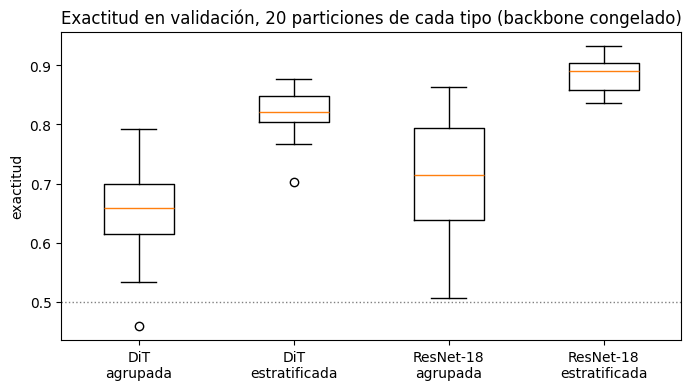

ResNet-18: la estratificada da 88.3% y la agrupada 70.5% --> 17.8 puntos de optimismo.
DiT: la estratificada da 82.0% y la agrupada 64.7% --> 17.2 puntos de optimismo.


In [ ]:
N_REPETICIONES = 20
filas = []
for backbone, X in vectores.items():
    for s in range(N_REPETICIONES):
        _, va_g, _ = particion_por_familia(meta, semilla=s)
        tr_g = np.setdiff1d(np.arange(len(meta)), va_g)
        tr_e, va_e = train_test_split(np.arange(len(meta)), test_size=len(va_g),
                                      stratify=meta["familia"], random_state=s)
        for particion, tr, va in [("agrupada", tr_g, va_g), ("estratificada", tr_e, va_e)]:
            clf = logistica().fit(X[tr], y_sint[tr])
            filas.append({"backbone": backbone, "particion": particion, "semilla": s,
                          "exactitud_val": accuracy_score(y_sint[va], clf.predict(X[va]))})
df_part = pd.DataFrame(filas)

resumen = df_part.groupby(["backbone", "particion"])["exactitud_val"].agg(["mean", "std", "min", "max"])
display(resumen.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
etiquetas_box, datos_box = [], []
for (backbone, particion), g in df_part.groupby(["backbone", "particion"]):
    etiquetas_box.append(f"{backbone}\n{particion}")
    datos_box.append(g["exactitud_val"].values)
ax.boxplot(datos_box)
ax.set_xticks(range(1, len(etiquetas_box) + 1), etiquetas_box)
ax.axhline(0.5, color="gray", ls=":", lw=1)
ax.set(title=f"Exactitud en validación, {N_REPETICIONES} particiones de cada tipo (backbone congelado)",
       ylabel="exactitud")
plt.show()

for backbone in vectores:
    m = resumen.loc[backbone, "mean"]
    print(f"{backbone}: la estratificada da {m['estratificada']:.1%} y la agrupada {m['agrupada']:.1%} "
          f"--> {100 * (m['estratificada'] - m['agrupada']):.1f} puntos de optimismo.")

**Cómo leerlo.**
- **La distancia entre las cajas** de un mismo backbone es el optimismo de la estratificada: lo que el modelo "acierta" por haber visto la plantilla, no por entender qué es un recibo.
- **El largo de cada caja** es cuánto se mueve el resultado sólo por cambiar la partición. Si la agrupada es más larga, ese es el precio de la sección 4: depende mucho de qué familias quedaron afuera. Por eso un único número de validación agrupada hay que leerlo con esa dispersión al lado.
- **Entre backbones:** si DiT le gana a ResNet sobre todo en la agrupada, sus rasgos de "documento" generalizan mejor a diseños nuevos, que es justamente lo que esperábamos de un modelo pre-entrenado en documentos.

### 10.2 Familia por familia

`LeaveOneGroupOut`: el modelo se entrena con todas las familias menos una y predice esa. Se repite para cada una de las 20 familias. Al lado, la misma predicción con validación cruzada estratificada, donde la familia sí estuvo en entrenamiento. La diferencia por familia muestra **qué diseños sólo se reconocen si ya se vieron**.

In [ ]:
tabla_familias = meta[["clase", "familia"]].copy()
for backbone, X in vectores.items():
    sin_verla = cross_val_predict(logistica(), X, y_sint, groups=familias, cv=LeaveOneGroupOut())
    pliegues = list(StratifiedKFold(5, shuffle=True, random_state=SEMILLA).split(X, familias))
    viendola = cross_val_predict(logistica(), X, y_sint, cv=pliegues)
    tabla_familias[f"{backbone} sin verla"] = sin_verla == y_sint
    tabla_familias[f"{backbone} viéndola"] = viendola == y_sint

por_familia = tabla_familias.groupby(["clase", "familia"]).mean().round(2)
por_familia["DiT: costo de no verla"] = por_familia["DiT viéndola"] - por_familia["DiT sin verla"]
display(por_familia.sort_values("DiT: costo de no verla", ascending=False))

if "recibo_vacio" in por_familia.index.get_level_values("familia"):
    fila = por_familia.xs("recibo_vacio", level="familia").iloc[0]
    print(f"recibo_vacio: si el modelo NUNCA vio un recibo vacío, acierta {fila['DiT sin verla']:.0%} (DiT) "
          f"y {fila['ResNet-18 sin verla']:.0%} (ResNet). Por eso en 4.2 lo dejamos siempre en entrenamiento.")

ResNet-18 sin verla  ResNet-18 viéndola  \
clase     familia                                                       
no_recibo presupuesto                        0.65                0.76   
recibo    periodos                           0.80                0.95   
no_recibo recibo_vacio                       0.31                0.94   
recibo    matriz                             0.30                0.95   
no_recibo estado_cuenta                      0.53                0.76   
recibo    listado_largo                      0.35                0.75   
          formulario                         0.45                0.85   
no_recibo planilla_horas                     0.56                0.81   
          carta                              0.56                1.00   
          constancia_laboral                 0.81                0.88   
          factura                            0.29                0.88   
          ticket                             1.00                1.00   
          tributo_municipal                  0.50                1.00   
recibo    sistema_viejo                      0.90                0.95   
          lado_a_lado                        0.75                0.85   
no_recibo recibo_pago                        0.88                0.88   
recibo    generico_limpio                    0.95                1.00   
          tabla_densa                        0.95                0.95   
          bloques                            0.60                0.90   
no_recibo factura_servicios                  1.00                1.00   

                              DiT sin verla  DiT viéndola  \
clase     familia                                           
no_recibo presupuesto                  0.12          0.76   
recibo    periodos                     0.25          0.85   
no_recibo recibo_vacio                 0.06          0.62   
recibo    matriz                       0.25          0.80   
no_recibo estado_cuenta                0.29          0.71   
recibo    listado_largo                0.60          0.90   
          formulario                   0.45          0.65   
no_recibo planilla_horas               0.75          0.94   
          carta                        0.69          0.81   
          constancia_laboral           0.69          0.81   
          factura                      0.76          0.88   
          ticket                       0.82          0.94   
          tributo_municipal            0.88          1.00   
recibo    sistema_viejo                0.90          1.00   
          lado_a_lado                  0.75          0.85   
no_recibo recibo_pago                  0.69          0.75   
recibo    generico_limpio              0.75          0.80   
          tabla_densa                  0.85          0.90   
          bloques                      0.90          0.95   
no_recibo factura_servicios            1.00          1.00   

                              DiT: costo de no verla  
clase     familia                                     
no_recibo presupuesto                           0.64  
recibo    periodos                              0.60  
no_recibo recibo_vacio                          0.56  
recibo    matriz                                0.55  
no_recibo estado_cuenta                         0.42  
recibo    listado_largo                         0.30  
          formulario                            0.20  
no_recibo planilla_horas                        0.19  
          carta                                 0.12  
          constancia_laboral                    0.12  
          factura                               0.12  
          ticket                                0.12  
          tributo_municipal                     0.12  
recibo    sistema_viejo                         0.10  
          lado_a_lado                           0.10  
no_recibo recibo_pago                           0.06  
recibo    generico_limpio                       0.05  
          tabla_densa              

recibo_vacio: si el modelo NUNCA vio un recibo vacío, acierta 6% (DiT) y 31% (ResNet). Por eso en 4.2 lo dejamos siempre en entrenamiento.


---
## 11. El umbral: qué error preferimos

Hasta acá cortamos en 0,5. Pero el modelo devuelve una **probabilidad**, y dónde cortar es una **decisión del negocio**, no técnica (clase 9). Los dos errores no cuestan lo mismo:

- **Aceptar un no recibo** (falso positivo): un documento inválido pasa el control del onboarding. **Es el error caro.**
- **Rechazar un recibo** (falso negativo): el cliente tiene que volver a subirlo o se revisa a mano. Molesta, pero se arregla.

Por eso no proponemos un umbral sino **dos**, con una zona gris en el medio:

| P(recibo) | decisión |
|---|---|
| ≥ `U_ALTO` | **aceptar** automáticamente |
| entre `U_BAJO` y `U_ALTO` | **revisión manual** (como hoy) |
| < `U_BAJO` | **pedir otro documento** |

Los dos umbrales se eligen **en validación** (nunca en test):
- `U_ALTO`: apenas por encima del no recibo con más probabilidad --> en validación no se acepta ningún no recibo.
- `U_BAJO`: apenas por debajo del recibo con menos probabilidad --> en validación no se rechaza ningún recibo.

Sobre el diseño: `U_ALTO` nunca baja de 0,5 y `U_BAJO` nunca sube de 0,5. **Ojo:** "cero errores en 73 documentos de validación" es una regla exigente sobre muy pocos datos. En producción estos umbrales se recalibrarían con documentos reales del banco.

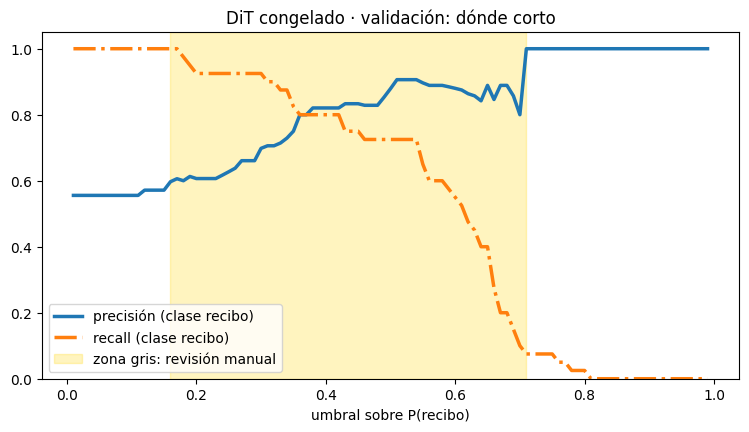

U_BAJO = 0.16 · U_ALTO = 0.71

decisión   aceptar  pedir otro  revisión manual
verdad                                         
no recibo        0           5               27
recibo           3           0               37

En validación, 11% de los documentos se resuelven solos y 89% van a revisión manual.


In [ ]:
p_val, y_val = elegido["eval_val"]["probs"], elegido["eval_val"]["etiquetas"]

# La curva de la clase 9: precisión y recall según dónde corto
umbrales = np.linspace(0.01, 0.99, 99)
precisiones = [precision_score(y_val, (p_val >= u).astype(int), zero_division=1) for u in umbrales]
recalls = [recall_score(y_val, (p_val >= u).astype(int), zero_division=0) for u in umbrales]

U_ALTO = float(np.clip(np.round(p_val[y_val == 0].max() + 0.01, 2), 0.5, 0.99))
U_BAJO = float(np.clip(np.round(p_val[y_val == 1].min() - 0.01, 2), 0.01, 0.5))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(umbrales, precisiones, lw=2.5, label="precisión (clase recibo)")
ax.plot(umbrales, recalls, lw=2.5, ls="-.", label="recall (clase recibo)")
ax.axvspan(U_BAJO, U_ALTO, color="gold", alpha=0.25, label="zona gris: revisión manual")
ax.set(title=f"{MODELO_ELEGIDO} · validación: dónde corto", xlabel="umbral sobre P(recibo)", ylim=(0, 1.05))
ax.legend()
plt.show()


def decidir(p: np.ndarray) -> np.ndarray:
    return np.where(p >= U_ALTO, "aceptar", np.where(p < U_BAJO, "pedir otro", "revisión manual"))


decision_val = decidir(p_val)
print(f"U_BAJO = {U_BAJO:.2f} · U_ALTO = {U_ALTO:.2f}\n")
print(pd.crosstab(pd.Series(np.where(y_val == 1, "recibo", "no recibo"), name="verdad"),
                  pd.Series(decision_val, name="decisión")))
automatico = (decision_val != "revisión manual").mean()
print(f"\nEn validación, {automatico:.0%} de los documentos se resuelven solos y "
      f"{1 - automatico:.0%} van a revisión manual.")

---
## 12. El sobre cerrado: test con documentos reales

Regla de oro de la clase 4: el test se abre **una sola vez**, al final, con todo ya decidido: el modelo (9.2) y los umbrales (11). Mostramos los cuatro modelos para la presentación, pero la elección ya está hecha y no se cambia por lo que salga acá.

Los PDF se pasan a imagen con `DPI_PDF`, y todo entra por la misma `preparar()` que los sintéticos: gris y 224×224.

**Antes de leer los números:** son 22 documentos y sólo 7 negativos --> cada negativo mal clasificado mueve la precisión varios puntos. No es una estimación del desempeño en producción, es una **prueba de cordura**: ¿lo aprendido con sintéticos sirve con papeles reales?

In [ ]:
imagenes_test = [preparar(r) for r in df_test["ruta"]]
y_test = df_test["etiqueta"].values


@torch.no_grad()
def predecir(modelo: nn.Module, tf_eval, imagenes: list) -> np.ndarray:
    modelo.eval()
    ds = DocumentosDataset(imagenes, np.zeros(len(imagenes)), tf_eval)
    return np.concatenate([torch.softmax(modelo(x.to(device)), dim=1)[:, 1].cpu().numpy()
                           for x, _ in DataLoader(ds, batch_size=64)])


filas = []
for nombre, r in resultados.items():
    p = predecir(r["modelo"], r["tfs"]["val"], imagenes_test)
    df_test[f"p_{nombre}"] = p
    for grupo in ["todos", CON_PARIENTE, NO_VISTO]:
        m = np.ones(len(df_test), bool) if grupo == "todos" else (df_test["grupo"] == grupo).values
        filas.append({"modelo": nombre, "grupo": grupo, "n": int(m.sum()),
                      **metricas(y_test[m], p[m])})
tabla_test = pd.DataFrame(filas).set_index(["modelo", "grupo"])
print("Test real, umbral 0,5 (en 'diseño no visto' sólo hay recibos --> la precisión no informa):")
display(tabla_test.round(2))

Test real, umbral 0,5 (en 'diseño no visto' sólo hay recibos --> la precisión no informa):


n  exactitud  precision  \
modelo                grupo                                              
ResNet-18 congelada   todos                   22       0.45       0.62   
                      con pariente sintético  17       0.53       0.58   
                      diseño no visto          5       0.20       1.00   
ResNet-18 fine-tuning todos                   22       0.55       0.67   
                      con pariente sintético  17       0.65       0.64   
                      diseño no visto          5       0.20       1.00   
DiT congelado         todos                   22       0.64       0.67   
                      con pariente sintético  17       0.53       0.56   
                      diseño no visto          5       1.00       1.00   
DiT fine-tuning       todos                   22       0.68       0.79   
                      con pariente sintético  17       0.65       0.70   
                      diseño no visto          5       0.80       1.00   

                                              recall    f1  
modelo                grupo                                 
ResNet-18 congelada   todos                     0.53  0.57  
                      con pariente sintético    0.70  0.64  
                      diseño no visto           0.20  0.33  
ResNet-18 fine-tuning todos                     0.67  0.67  
                      con pariente sintético    0.90  0.75  
                      diseño no visto           0.20  0.33  
DiT congelado         todos                     0.93  0.78  
                      con pariente sintético    0.90  0.69  
                      diseño no visto           1.00  1.00  
DiT fine-tuning       todos                     0.73  0.76  
                      con pariente sintético    0.70  0.70  
                      diseño no visto           0.80  0.89

DiT congelado · TEST real · umbral 0,5
· Precisión 0.67: de cada 100 documentos que el modelo llamó recibo, 67 lo eran.
· Recall 0.93: de cada 100 recibos verdaderos, el modelo reconoció 93.
· No recibos que dejó pasar como recibo (el error caro): 7 de 7.
· Recibos que rechazó (van a molestar al cliente o a revisión): 1 de 15.


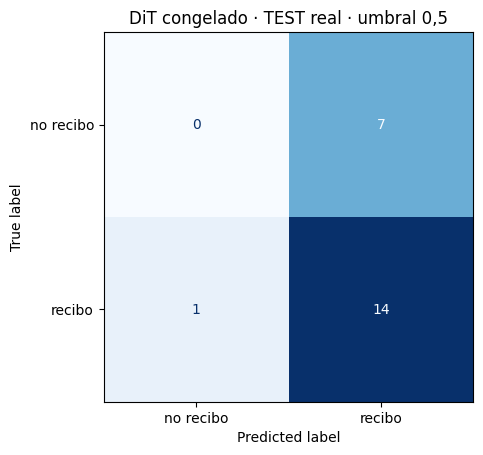

Con los umbrales de la sección 11 (U_BAJO=0.16, U_ALTO=0.71):
decision                          aceptar  revisión manual
grupo                  etiqueta                           
con pariente sintético no recibo        1                6
                       recibo           1                9
diseño no visto        recibo           2                3 



,archivo,nota,grupo,etiqueta,p_DiT congelado,decision
17,im_contribucion.jpeg,tributo municipal,con pariente sintético,0,0.566,revisión manual
19,ose2.jpeg,factura de servicio,con pariente sintético,0,0.578,revisión manual
16,estado_cuenta_scotia.jpeg,"estado de cuenta tarjeta, girado",con pariente sintético,0,0.582,revisión manual
18,ose.jpeg,factura de servicio,con pariente sintético,0,0.584,revisión manual
21,recibo_generico_sin_datos2.webp,recibo VACÍO,con pariente sintético,0,0.600,revisión manual
15,estado_cuenta_santander.jpeg,estado de cuenta tarjeta,con pariente sintético,0,0.691,revisión manual
20,recibo_generico_sin_datos.webp,recibo VACÍO,con pariente sintético,0,0.714,aceptar
3,bps.webp,BPS por períodos,con pariente sintético,1,0.483,revisión manual
8,generico_con_datos2.webp,genérico,con pariente sintético,1,0.549,revisión manual
12,accesa_3.pdf,"Accesa, dos recibos en una hoja",diseño no visto,1,0.557,revisión manual


In [ ]:
p_test = df_test[f"p_{MODELO_ELEGIDO}"].values
df_test["decision"] = decidir(p_test)

reportar(y_test, (p_test >= 0.5).astype(int), f"{MODELO_ELEGIDO} · TEST real · umbral 0,5")

print(f"Con los umbrales de la sección 11 (U_BAJO={U_BAJO:.2f}, U_ALTO={U_ALTO:.2f}):")
print(pd.crosstab([df_test["grupo"], df_test["etiqueta"].map({1: "recibo", 0: "no recibo"})],
                  df_test["decision"]), "\n")

display(df_test[["archivo", "nota", "grupo", "etiqueta", f"p_{MODELO_ELEGIDO}", "decision"]]
        .sort_values(["etiqueta", f"p_{MODELO_ELEGIDO}"]).round(3))

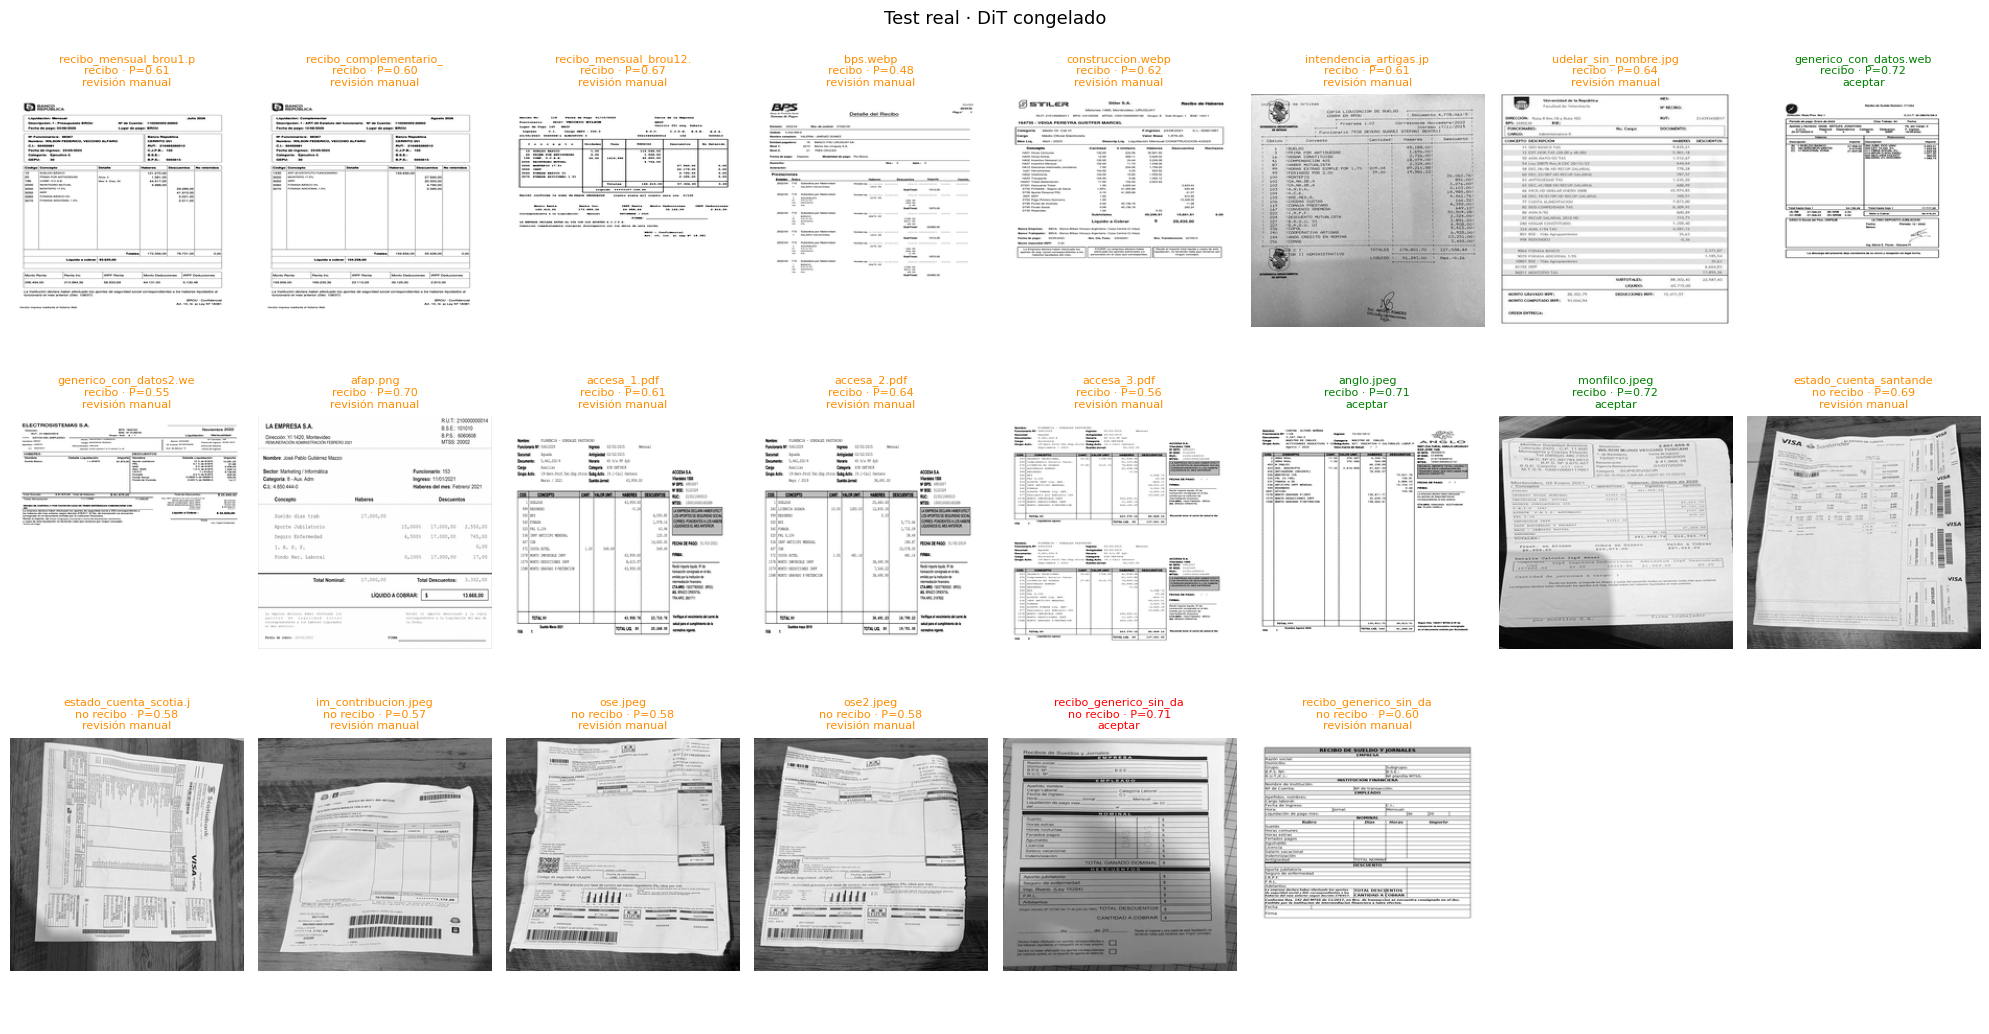

In [ ]:
# Los 22 documentos, con lo que dijo el modelo elegido. Verde = decisión correcta, rojo = incorrecta, naranja = revisión manual
colores = {"aceptar": 1, "pedir otro": 0}
fig, ejes = plt.subplots(3, 8, figsize=(20, 10.5))
for ax in ejes.flat:
    ax.axis("off")
for ax, (_, fila), img in zip(ejes.flat, df_test.iterrows(), imagenes_test):
    d = fila["decision"]
    color = "darkorange" if d == "revisión manual" else ("green" if colores[d] == fila["etiqueta"] else "red")
    ax.imshow(img, cmap="gray")
    ax.set_title(f"{fila['archivo'][:22]}\n{'recibo' if fila['etiqueta'] else 'no recibo'} · "
                 f"P={fila[f'p_{MODELO_ELEGIDO}']:.2f}\n{d}", fontsize=8, color=color)
plt.suptitle(f"Test real · {MODELO_ELEGIDO}", fontsize=13)
plt.tight_layout()
plt.show()

---
## 13. ¿Dónde miró el modelo? (oclusión) Candidato a sacar

Herramienta de la clase 5: **tapar y ver**. Tapamos un cuadrado de la imagen con blanco (el color del papel) y medimos cuánto **baja** la probabilidad de la clase correcta. Movemos el cuadrado por toda la hoja. Donde tapar duele, ahí estaba mirando.

Lo que esperaríamos de un modelo que entendió el concepto: que mire la **tabla de haberes y descuentos**, el **encabezado** (empresa, BPS, funcionario) o el **líquido a cobrar**. Lo preocupante sería que mire bordes, sombras o el fondo de la foto --> atajo.

Advertencia de la clase 5: estos mapas son **pistas, no la verdad**. Dependen del tamaño del cuadrado y de con qué se tapa.

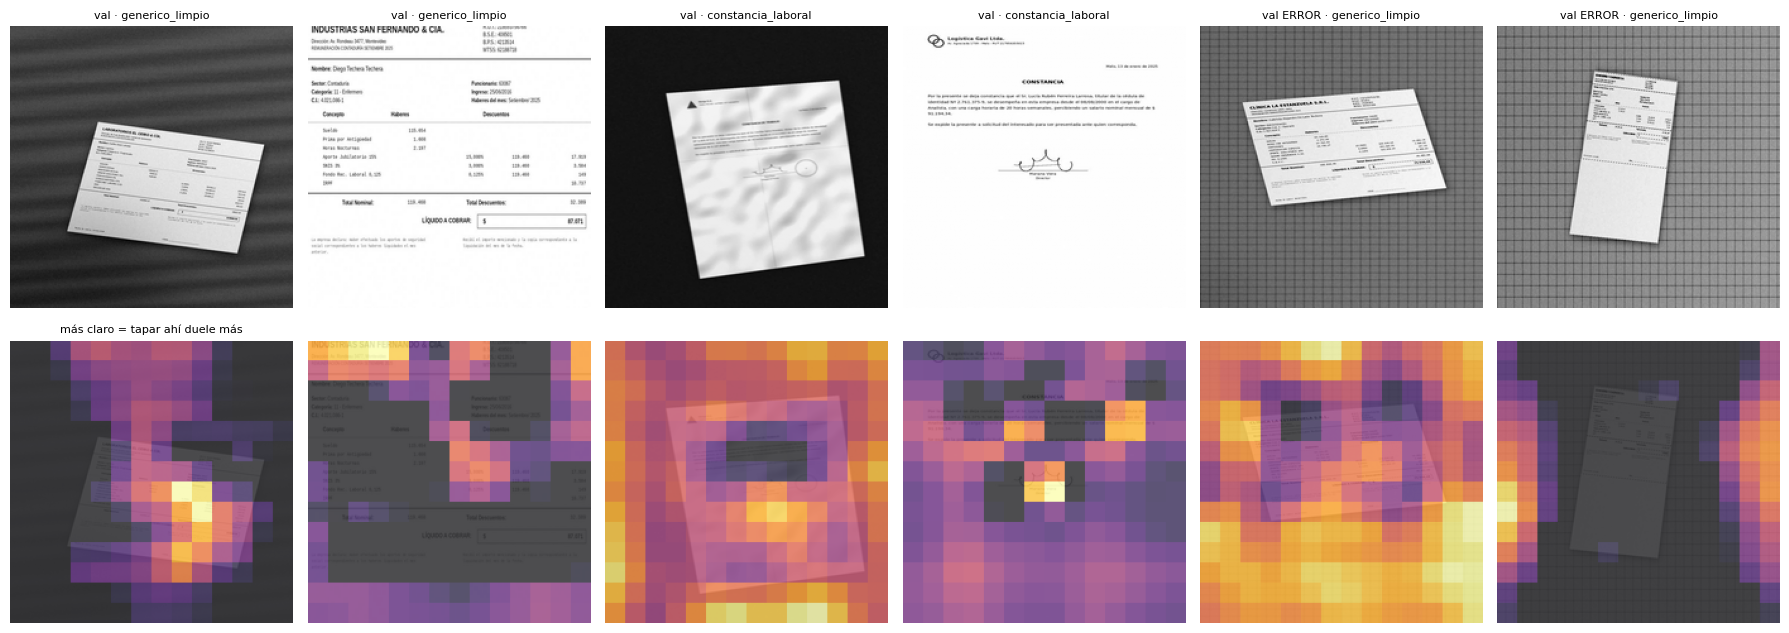

In [ ]:
 ||@torch.no_grad()
def mapa_de_oclusion(modelo: nn.Module, x: torch.Tensor, clase: int, relleno: torch.Tensor,
                     lado: int = 32, paso: int = 16) -> np.ndarray:
    """Cuánto baja P(clase) al tapar cada cuadrado de lado x lado píxeles (clase 5, adaptada a 3 canales)."""
    modelo.eval()
    _, alto, ancho = x.shape
    p_original = torch.softmax(modelo(x.unsqueeze(0).to(device)), 1)[0, clase].item()
    tapadas, lugares = [], []
    for f in range(0, alto - lado + 1, paso):
        for c in range(0, ancho - lado + 1, paso):
            t = x.clone()
            t[:, f:f + lado, c:c + lado] = relleno.view(3, 1, 1)     # tapamos con "papel blanco"
            tapadas.append(t)
            lugares.append((f, c))
    p = torch.cat([torch.softmax(modelo(torch.stack(tapadas[k:k + 64]).to(device)), 1)[:, clase].cpu()
                   for k in range(0, len(tapadas), 64)])
    caida, veces = np.zeros((alto, ancho)), np.zeros((alto, ancho))
    for (f, c), pk in zip(lugares, p.tolist()):
        caida[f:f + lado, c:c + lado] += p_original - pk
        veces[f:f + lado, c:c + lado] += 1
    return caida / np.maximum(veces, 1)


def mostrar_oclusion(casos: list, modelo: nn.Module, tfs: dict, media: list, desvio: list) -> None:
    """casos: lista de (título, imagen PIL ya preparada, etiqueta verdadera)."""
    blanco = (torch.ones(3) - torch.tensor(media)) / torch.tensor(desvio)    # el blanco, ya normalizado
    fig, ejes = plt.subplots(2, len(casos), figsize=(3 * len(casos), 6.6), squeeze=False)
    for j, (titulo, img, etiqueta) in enumerate(casos):
        x = tfs["val"](img)
        mapa = mapa_de_oclusion(modelo, x, etiqueta, blanco)
        ejes[0, j].imshow(img, cmap="gray")
        ejes[0, j].set_title(titulo, fontsize=8)
        ejes[1, j].imshow(img, cmap="gray", alpha=0.4)
        ejes[1, j].imshow(np.clip(mapa, 0, None), cmap="inferno", alpha=0.7)
        for ax in ejes[:, j]:
            ax.axis("off")
    ejes[1, 0].set_title("más claro = tapar ahí duele más", fontsize=8)
    plt.tight_layout()
    plt.show()


media_el = IMAGENET_MEDIA if MODELO_ELEGIDO.startswith("ResNet") else DIT_MEDIA
desvio_el = IMAGENET_DESVIO if MODELO_ELEGIDO.startswith("ResNet") else DIT_DESVIO

# Validación: dos aciertos por clase (de las familias que el modelo no vio), más hasta dos errores
casos = []
for etiqueta in [1, 0]:
    for i in val.index[val["acierto"] & (y_sint[val.index] == etiqueta)][:2]:
        casos.append((f"val · {meta.at[i, 'familia']}", imagenes_sinteticas[i], etiqueta))
for i in errores.index[:2]:
    casos.append((f"val ERROR · {meta.at[i, 'familia']}", imagenes_sinteticas[i], int(y_sint[i])))
mostrar_oclusion(casos, elegido["modelo"], elegido["tfs"], media_el, desvio_el)

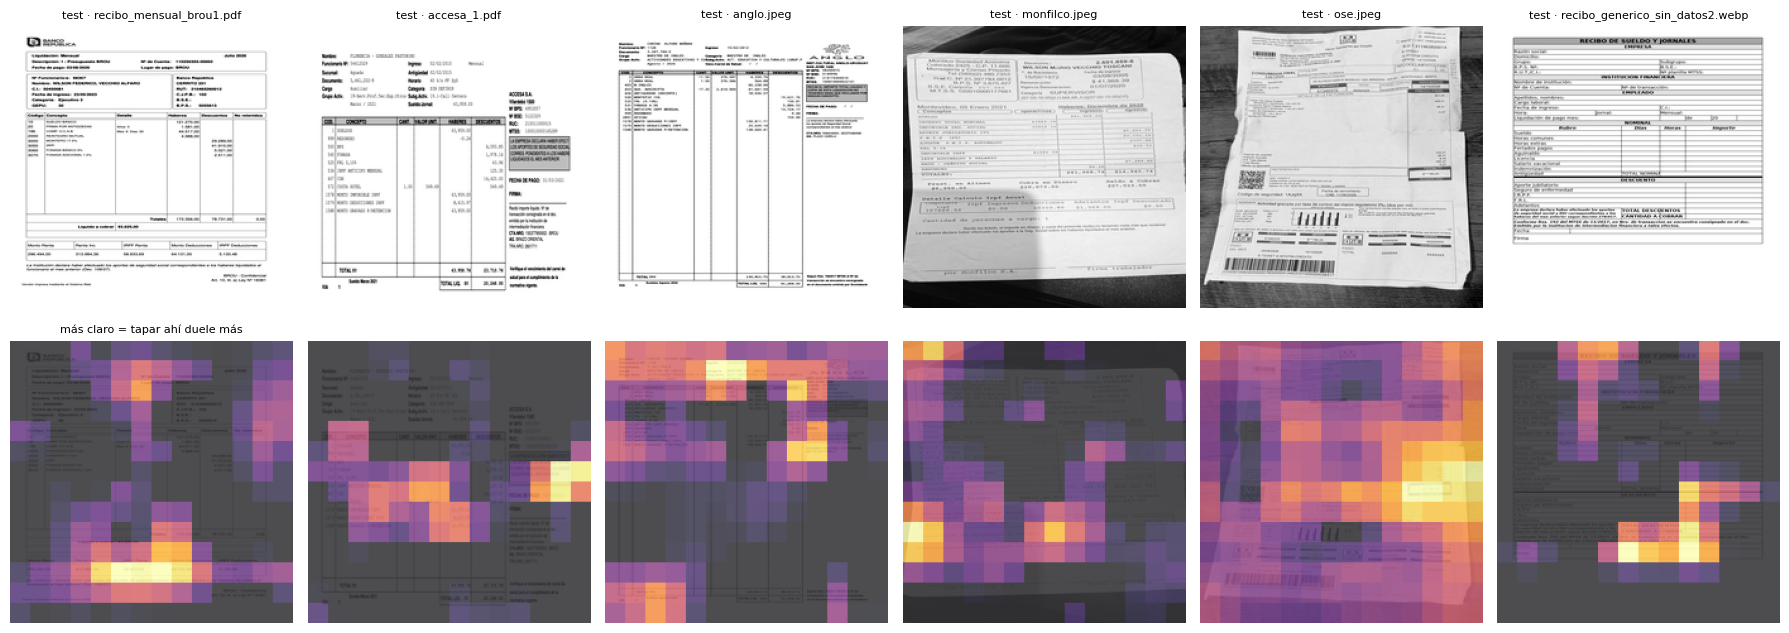

In [ ]:
# Test: los diseños no vistos y los negativos más parecidos a un recibo
interesantes = ["accesa_1.pdf", "anglo.jpeg", "monfilco.jpeg", "recibo_mensual_brou1.pdf",
                "recibo_generico_sin_datos2.webp", "ose.jpeg"]
casos = [(f"test · {df_test.at[k, 'archivo']}", imagenes_test[k], int(df_test.at[k, "etiqueta"]))
         for k in df_test.index[df_test["archivo"].isin(interesantes)]]
mostrar_oclusion(casos, elegido["modelo"], elegido["tfs"], media_el, desvio_el)

---
## 14. Reproducibilidad y ficha del modelo

La función de la clase 10, adaptada: versiones, semilla, hash de los datos (si el zip cambia, cambia el hash) y hash de los pesos del modelo elegido. Además, la **ficha del modelo** (clase 10): qué mide, con qué se entrenó, cómo le fue y qué limitaciones conocemos.

In [ ]:
def hash_archivo(ruta) -> str:
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()


def bloque_de_reproducibilidad() -> str:
    pesos = b"".join(v.detach().cpu().numpy().tobytes() for v in elegido["modelo"].state_dict().values())
    commit_dit = getattr(AutoModel.from_pretrained(MODELO_DIT, revision=REVISION_DIT).config, "_commit_hash", None)
    lineas = ["=" * 72, "BLOQUE DE REPRODUCIBILIDAD", "=" * 72,
              f"Fecha de la corrida       : {date.today().isoformat()}",
              f"Semilla                   : {SEMILLA}",
              f"Python                    : {platform.python_version()} ({platform.system()})",
              f"torch / torchvision       : {torch.__version__} / {torchvision.__version__}",
              f"transformers              : {transformers.__version__}",
              f"device                    : {device}",
              f"Datos sintéticos (sha256) : {hash_archivo(ZIP_SINTETICOS)[:16]}…  ({len(meta)} imágenes)",
              f"Partición de validación   : familias {familias_val}",
              f"DiT                       : {MODELO_DIT} @ {commit_dit}",
              f"Modelo elegido            : {MODELO_ELEGIDO}",
              f"Hash de sus pesos         : {hashlib.sha256(pesos).hexdigest()[:16]}…",
              f"Umbrales                  : U_BAJO={U_BAJO:.2f} · U_ALTO={U_ALTO:.2f}",
              "=" * 72]
    return "\n".join(lineas)


print(bloque_de_reproducibilidad())

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

[transformers] BeitModel LOAD REPORT from: microsoft/dit-base-finetuned-rvlcdip
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BLOQUE DE REPRODUCIBILIDAD
Fecha de la corrida       : 2026-11-22
Semilla                   : 1983
Python                    : 3.13.16 (Linux)
torch / torchvision       : 2.14.1+cu130 / 0.29.1+cu130
transformers              : 5.22.1
device                    : cuda
Datos sintéticos (sha256) : e962440d6ecab796…  (360 imágenes)
Partición de validación   : familias ['generico_limpio', 'formulario', 'factura_servicios', 'constancia_laboral']
DiT                       : microsoft/dit-base-finetuned-rvlcdip @ None
Modelo elegido            : DiT congelado
Hash de sus pesos         : e003c9518c8b7a84…
Umbrales                  : U_BAJO=0.16 · U_ALTO=0.71


In [ ]:
fila_val = tabla_val.loc[MODELO_ELEGIDO]
fila_test = tabla_test.loc[(MODELO_ELEGIDO, "todos")]
fila_nv = tabla_test.loc[(MODELO_ELEGIDO, NO_VISTO)]
optimismo = resumen.loc["DiT", "mean"]

FICHA = f"""
# Ficha del modelo — ¿es un recibo de sueldo?

**Versión.** 1.0 · {date.today().isoformat()} · semilla {SEMILLA} · {MODELO_ELEGIDO}

## Qué mide
Si una imagen de un documento es un recibo de sueldo COMPLETO (con datos). Un formulario de
recibo vacío cuenta como "no recibo". NO verifica que el recibo sea auténtico, ni que los datos
coincidan con los de la persona, ni que esté vigente.

## Con qué se entrenó
{len(idx_train)} documentos sintéticos (9 familias de recibos y 11 categorías de no recibos menos
las de validación), generados por nosotros con datos ficticios. Validación: {len(idx_val)} documentos de
familias que el modelo nunca vio ({", ".join(familias_val)}).

## Desempeño
- Validación agrupada (umbral 0,5): exactitud {fila_val['exactitud']:.2f}, precisión {fila_val['precision']:.2f},
  recall {fila_val['recall']:.2f}, F1 {fila_val['f1']:.2f}.
- Test real ({int(fila_test['n'])} documentos): exactitud {fila_test['exactitud']:.2f}, precisión {fila_test['precision']:.2f},
  recall {fila_test['recall']:.2f}. Recibos de diseño no visto: recall {fila_nv['recall']:.2f} ({int(fila_nv['n'])} documentos).
- Variabilidad según la partición (backbone DiT congelado, {N_REPETICIONES} particiones agrupadas):
  {optimismo['agrupada']:.2f} de exactitud media; con partición estratificada daría {optimismo['estratificada']:.2f}.

## Uso propuesto
Aceptar si P(recibo) ≥ {U_ALTO:.2f}, pedir otro documento si < {U_BAJO:.2f}, revisión manual en el medio.

## Limitaciones conocidas
1. Entrenado sólo con documentos sintéticos: el test real es chico (22 documentos, 7 negativos).
2. Ve el documento a 224x224 en gris: no lee el texto. Un recibo y un formulario con la misma
   estructura pueden confundirse.
3. Los formatos de recibo del generador salen de pocos ejemplos reales: empleadores con formatos
   muy distintos pueden fallar (ver "diseño no visto").
4. Umbrales calibrados con {len(idx_val)} documentos sintéticos: hay que recalibrarlos con datos reales.
"""
print(FICHA)


# Ficha del modelo — ¿es un recibo de sueldo?

**Versión.** 1.0 · 2026-11-22 · semilla 1983 · DiT congelado

## Qué mide
Si una imagen de un documento es un recibo de sueldo COMPLETO (con datos). Un formulario de
recibo vacío cuenta como "no recibo". NO verifica que el recibo sea auténtico, ni que los datos
coincidan con los de la persona, ni que esté vigente.

## Con qué se entrenó
288 documentos sintéticos (9 familias de recibos y 11 categorías de no recibos menos
las de validación), generados por nosotros con datos ficticios. Validación: 72 documentos de
familias que el modelo nunca vio (generico_limpio, formulario, factura_servicios, constancia_laboral).

## Desempeño
- Validación agrupada (umbral 0,5): exactitud 0.79, precisión 0.88,
  recall 0.72, F1 0.79.
- Test real (22 documentos): exactitud 0.64, precisión 0.67,
  recall 0.93. Recibos de diseño no visto: recall 1.00 (5 documentos).
- Variabilidad según la partición (backbone DiT congelado, 20 particiones agrupadas):
  0.65 d

Opcional: guardar los pesos del modelo elegido en la carpeta del obligatorio, para usarlo sin reentrenar (`load_state_dict`, clase 10).

In [ ]:
GUARDAR_MODELO = False   # True para guardar los pesos en Drive

if GUARDAR_MODELO:
    destino = CARPETA_OBLIGATORIO / f"modelo_{MODELO_ELEGIDO.replace(' ', '_')}.pt"
    torch.save(elegido["modelo"].state_dict(), destino)
    print("Guardado en", destino)

---
## 15. Conclusiones y caminos para seguir

*(Completar después de correr el notebook completo: los números dependen de la corrida.)*

### 15.1 Qué encontramos

- **¿Le ganamos al piso?** TODO: exactitud del modelo tonto (sección 3) vs. la del modelo elegido (9.2).
- **¿ResNet o DiT? ¿Congelado o fine-tuning?** TODO: la tabla 9.2, y si se cumplió que el pre-entrenamiento en documentos generaliza mejor a diseños nuevos (10.1).
- **¿Cuánto mentía la estratificada?** TODO: los puntos de optimismo de la sección 10.1 y qué familias sólo se reconocen si se vieron (10.2).
- **¿Sirve con papeles reales?** TODO: test con pariente vs. diseño no visto (sección 12).
- **¿Dónde mira?** TODO: lo que muestran los mapas de oclusión (sección 13).

### 15.2 Problemas que tuvimos

- **Sin datos:** no hay datasets públicos de recibos uruguayos --> tuvimos que generar los nuestros.
- **Atajos en el generador:** la orientación (28 % de recibos apaisados vs. 4 % de negativos) y el color (papel amarillento sólo en `matriz`). Se detectaron con el modelo tonto (sección 3) y se corrigieron en el generador y con la escala de grises.
- **Validación optimista:** la estratificada mezcla plantillas entre train y val (secciones 4 y 10).
- **El recibo vacío:** es una regla de negocio. Si no hay ejemplos, el modelo no la puede aprender (10.2).
- TODO: agregar lo que aparezca al correr (sobreajuste, inestabilidad del fine-tuning, errores puntuales).

### 15.3 Caminos para seguir

- **Leer el texto:** modelos multimodales como **LayoutLMv3** o **Donut** combinan la imagen con el texto y su posición. Podrían usar palabras como "líquido", "BPS" o "IRPF" y separar un recibo completo de uno vacío, que a 224×224 en gris es difícil.
- **Más datos reales** para validar y, sobre todo, para calibrar los umbrales: recibos de otros empleadores (anonimizados) y lo que la gente sube por error en el onboarding.
- **Recortar el documento antes de clasificar:** en las fotos, la hoja ocupa a veces menos de la mitad del cuadro y a 224×224 se pierde detalle. Un paso previo que detecte los bordes de la hoja y la enderece le daría al modelo más píxeles útiles.
- **Más familias en el generador:** cada familia nueva suma diversidad de diseño, que es lo que mide la validación agrupada.
- **Validación cruzada agrupada para elegir el modelo,** en vez de una sola partición, con el fine-tuning completo y no sólo con el backbone congelado.
- **Validez:** pares mínimos (clase 10), como el mismo recibo completo vs. vacío, o con y sin la tabla de haberes, para confirmar qué está usando el modelo.